# BCSE331L  Course Project Final Documents

**Name:** Nagi Reddy SaiBaba  **Reg No.:** 23BDS0019

Module 2 to Module 7

Explaining Video Link : https://drive.google.com/file/d/1pMGS9ZEOhpJBA_XwimtoHjr4jj2yFv2J/view?usp=sharing

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)

CSV_PATH = "PhDPublications.csv"   # dataset shared through e-mail

---
# DA-2 : Data Import, Transform and Basic Statistical Analysis
Import the given dataset and perform preliminary data exploration.

### 1. Import the given dataset (CSV) into Python

In [ ]:
data = pd.read_csv(CSV_PATH)
data

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0
...,...,...,...,...,...,...,...
910,911,11.0,male,yes,2.0,2.86,7.0
911,912,12.0,male,yes,1.0,4.29,35.0
912,913,12.0,male,yes,1.0,NaN,5.0
913,914,16.0,male,yes,0.0,1.74,21.0


### 2. Display the first 10 records of the dataset

In [ ]:
data.head(10)

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0
5,6,0.0,female,yes,2.0,3.59,2.0
6,7,0.0,female,no,0.0,3.19,3.0
7,8,0.0,male,yes,2.0,2.96,4.0
8,9,0.0,male,no,0.0,4.62,6.0
9,10,0.0,female,yes,0.0,1.25,0.0


### 3. Display the last 10 records of the dataset

In [ ]:
data.tail(10)

,rownames,articles,gender,married,kids,prestige,mentor
905,906,7.0,male,no,0.0,3.69,19.0
906,907,8.0,male,yes,0.0,2.51,11.0
907,908,9.0,male,yes,1.0,2.96,23.0
908,909,9.0,male,yes,1.0,1.86,47.0
909,910,10.0,female,NaN,0.0,3.59,18.0
910,911,11.0,male,yes,2.0,2.86,7.0
911,912,12.0,male,yes,1.0,4.29,35.0
912,913,12.0,male,yes,1.0,NaN,5.0
913,914,16.0,male,yes,0.0,1.74,21.0
914,915,19.0,male,yes,0.0,1.86,42.0


### 4. Find the total number of rows and columns

In [ ]:
print("dim  :", data.shape)
print("nrow :", data.shape[0])
print("ncol :", data.shape[1])

dim  : (915, 7)
nrow : 915
ncol : 7


### 5. Display the names of all variables (columns)

In [ ]:
print(data.columns.tolist())

['rownames', 'articles', 'gender', 'married', 'kids', 'prestige', 'mentor']


### 6. Display the data type (structure) of each variable

In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  915 non-null    int64  
 1   articles  913 non-null    float64
 2   gender    910 non-null    str    
 3   married   905 non-null    str    
 4   kids      909 non-null    float64
 5   prestige  904 non-null    float64
 6   mentor    913 non-null    float64
dtypes: float64(4), int64(1), str(2)
memory usage: 50.2 KB


### 7. Display the summary statistics of the dataset

In [ ]:
data.describe(include="all")

,rownames,articles,gender,married,kids,prestige,mentor
count,915.000000,913.000000,910,905,909.000000,904.000000,913.000000
unique,NaN,NaN,2,2,NaN,NaN,NaN
top,NaN,NaN,male,yes,NaN,NaN,NaN
freq,NaN,NaN,492,598,NaN,NaN,NaN
mean,458.000000,1.695509,NaN,NaN,0.492849,3.111753,8.782037
std,264.282046,1.927226,NaN,NaN,0.764870,0.981712,9.488545
min,1.000000,0.000000,NaN,NaN,0.000000,0.755000,0.000000
25%,229.500000,0.000000,NaN,NaN,0.000000,2.260000,3.000000
50%,458.000000,1.000000,NaN,NaN,0.000000,3.190000,6.000000
75%,686.500000,2.000000,NaN,NaN,1.000000,3.920000,12.000000


### 8. Determine the number of missing values in each column

In [ ]:
data.isna().sum()

rownames     0
articles     2
gender       5
married     10
kids         6
prestige    11
mentor       2
dtype: int64

### 9. Display the total number of missing values in the dataset

In [ ]:
print(data.isna().sum().sum())

36


### 10. Display the number of missing values in each column

In [ ]:
data.isna().sum()

rownames     0
articles     2
gender       5
married     10
kids         6
prestige    11
mentor       2
dtype: int64

### 11. Identify the rows containing at least one missing value

In [ ]:
missing_rows = data[data.isna().any(axis=1)]
print("Row numbers (rownames) with missing values:")
print(missing_rows["rownames"].tolist())

Row numbers (rownames) with missing values:
[17, 37, 42, 57, 63, 93, 102, 191, 235, 241, 252, 293, 352, 395, 431, 460, 466, 506, 518, 545, 565, 580, 617, 637, 643, 667, 686, 723, 729, 777, 814, 849, 868, 878, 910, 913]


### 12. Remove all rows containing missing values and display the cleaned dataset

In [ ]:
clean_df = data.dropna()
print(clean_df.shape)
clean_df

(879, 7)


,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0
...,...,...,...,...,...,...,...
908,909,9.0,male,yes,1.0,1.86,47.0
910,911,11.0,male,yes,2.0,2.86,7.0
911,912,12.0,male,yes,1.0,4.29,35.0
913,914,16.0,male,yes,0.0,1.74,21.0


### 13. Replace missing values in a selected numerical column using the mean of that column

In [ ]:
data["prestige"] = data["prestige"].fillna(data["prestige"].mean())
data.head(20)

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.520000,7.0
1,2,0.0,female,no,0.0,2.050000,6.0
2,3,0.0,female,no,0.0,3.750000,6.0
3,4,0.0,male,yes,1.0,1.180000,3.0
4,5,0.0,female,no,0.0,3.750000,26.0
5,6,0.0,female,yes,2.0,3.590000,2.0
6,7,0.0,female,no,0.0,3.190000,3.0
7,8,0.0,male,yes,2.0,2.960000,4.0
8,9,0.0,male,no,0.0,4.620000,6.0
9,10,0.0,female,yes,0.0,1.250000,0.0


### 14. Replace missing values in another numerical column using the median

In [ ]:
data["mentor"] = data["mentor"].fillna(data["mentor"].median())
data.head(20)

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.520000,7.0
1,2,0.0,female,no,0.0,2.050000,6.0
2,3,0.0,female,no,0.0,3.750000,6.0
3,4,0.0,male,yes,1.0,1.180000,3.0
4,5,0.0,female,no,0.0,3.750000,26.0
5,6,0.0,female,yes,2.0,3.590000,2.0
6,7,0.0,female,no,0.0,3.190000,3.0
7,8,0.0,male,yes,2.0,2.960000,4.0
8,9,0.0,male,no,0.0,4.620000,6.0
9,10,0.0,female,yes,0.0,1.250000,0.0


### 15. Replace missing values in a categorical column using the mode

In [ ]:
mode_gender = data["gender"].mode()[0]
data["gender"] = data["gender"].fillna(mode_gender)
print("Mode of gender:", mode_gender)
data.head(20)

Mode of gender: male


,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.520000,7.0
1,2,0.0,female,no,0.0,2.050000,6.0
2,3,0.0,female,no,0.0,3.750000,6.0
3,4,0.0,male,yes,1.0,1.180000,3.0
4,5,0.0,female,no,0.0,3.750000,26.0
5,6,0.0,female,yes,2.0,3.590000,2.0
6,7,0.0,female,no,0.0,3.190000,3.0
7,8,0.0,male,yes,2.0,2.960000,4.0
8,9,0.0,male,no,0.0,4.620000,6.0
9,10,0.0,female,yes,0.0,1.250000,0.0


### 16. Forward filling – replace missing values with the previous non-missing value (`na.locf`)

In [ ]:
data["prestige"] = data["prestige"].ffill()
data.head(10)

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0
5,6,0.0,female,yes,2.0,3.59,2.0
6,7,0.0,female,no,0.0,3.19,3.0
7,8,0.0,male,yes,2.0,2.96,4.0
8,9,0.0,male,no,0.0,4.62,6.0
9,10,0.0,female,yes,0.0,1.25,0.0


### 17. Backward filling – replace missing values with the next non-missing value

In [ ]:
data["mentor"] = data["mentor"].bfill()
data.head(10)

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0
5,6,0.0,female,yes,2.0,3.59,2.0
6,7,0.0,female,no,0.0,3.19,3.0
7,8,0.0,male,yes,2.0,2.96,4.0
8,9,0.0,male,no,0.0,4.62,6.0
9,10,0.0,female,yes,0.0,1.25,0.0


### 18. Replace remaining missing values with a constant value (0 or "Unknown")

In [ ]:
num_cols = data.select_dtypes(include="number").columns
data[num_cols] = data[num_cols].fillna(0)
data = data.fillna("Unknown")          # remaining text columns (e.g. married)
print("Missing values left:", data.isna().sum().sum())
data.head(20)

Missing values left: 0


,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.520000,7.0
1,2,0.0,female,no,0.0,2.050000,6.0
2,3,0.0,female,no,0.0,3.750000,6.0
3,4,0.0,male,yes,1.0,1.180000,3.0
4,5,0.0,female,no,0.0,3.750000,26.0
5,6,0.0,female,yes,2.0,3.590000,2.0
6,7,0.0,female,no,0.0,3.190000,3.0
7,8,0.0,male,yes,2.0,2.960000,4.0
8,9,0.0,male,no,0.0,4.620000,6.0
9,10,0.0,female,yes,0.0,1.250000,0.0


### 19. Remove duplicate records from the dataset

In [ ]:
data = data.drop_duplicates()
print(data.shape)
data.head()

(915, 7)


,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0


### 20. Convert appropriate variables into factors (categories)

In [ ]:
data["gender"] = data["gender"].astype("category")
data["married"] = data["married"].astype("category")
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   rownames  915 non-null    int64   
 1   articles  915 non-null    float64 
 2   gender    915 non-null    category
 3   married   915 non-null    category
 4   kids      915 non-null    float64 
 5   prestige  915 non-null    float64 
 6   mentor    915 non-null    float64 
dtypes: category(2), float64(4), int64(1)
memory usage: 37.7 KB


### 21. Rename one or more column names

In [ ]:
data = data.rename(columns={"articles": "publications"})
print(data.columns.tolist())

['rownames', 'publications', 'gender', 'married', 'kids', 'prestige', 'mentor']


### 22. Create a new derived column using existing variables

In [ ]:
data["total_score"] = data["publications"] + data["mentor"]
data.head()

,rownames,publications,gender,married,kids,prestige,mentor,total_score
0,1,0.0,male,yes,0.0,2.52,7.0,7.0
1,2,0.0,female,no,0.0,2.05,6.0,6.0
2,3,0.0,female,no,0.0,3.75,6.0,6.0
3,4,0.0,male,yes,1.0,1.18,3.0,3.0
4,5,0.0,female,no,0.0,3.75,26.0,26.0


### 23. Display the summary statistics of the dataset

In [ ]:
data.describe(include="all")

,rownames,publications,gender,married,kids,prestige,mentor,total_score
count,915.000000,915.000000,915,915,915.000000,915.000000,915.000000,915.000000
unique,NaN,NaN,2,3,NaN,NaN,NaN,NaN
top,NaN,NaN,male,yes,NaN,NaN,NaN,NaN
freq,NaN,NaN,497,598,NaN,NaN,NaN,NaN
mean,458.000000,1.691803,NaN,NaN,0.489617,3.111753,8.775956,10.467760
std,264.282046,1.926746,NaN,NaN,0.763393,0.975786,9.479049,10.233585
min,1.000000,0.000000,NaN,NaN,0.000000,0.755000,0.000000,0.000000
25%,229.500000,0.000000,NaN,NaN,0.000000,2.260000,3.000000,4.000000
50%,458.000000,1.000000,NaN,NaN,0.000000,3.150000,6.000000,7.000000
75%,686.500000,2.000000,NaN,NaN,1.000000,3.920000,12.000000,14.000000


### 24. Find the minimum and maximum values

In [ ]:
print("Min prestige:", data["prestige"].min())
print("Max prestige:", data["prestige"].max())

Min prestige: 0.754999995
Max prestige: 4.619999886


### 25. Calculate the range of a numerical variable

In [ ]:
print("Range:", [data["prestige"].min(), data["prestige"].max()])
print("Range width:", data["prestige"].max() - data["prestige"].min())

Range: [np.float64(0.754999995), np.float64(4.619999886)]
Range width: 3.8649998909999996


### 26. Calculate the variance

In [ ]:
print(data["prestige"].var())     # sample variance, same as R var()

0.9521589020370007


### 27. Calculate the standard deviation

In [ ]:
print(data["prestige"].std())     # sample sd, same as R sd()

0.9757862993693859


### 28. Calculate the interquartile range (IQR)

In [ ]:
q1, q3 = data["prestige"].quantile([0.25, 0.75])
print("IQR:", q3 - q1)

IQR: 1.6600000860000002


---
# DA-3 : Data Cleaning and Univariate Analysis
(R used dplyr, tidyr, ggplot2, stringr, forcats → pandas, matplotlib, seaborn)

### 1. Import a dataset (dataset shared through e-mail)

In [ ]:
df = pd.read_csv(CSV_PATH)
df.head()

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0


### 2. Display the first and last six records of the dataset

In [ ]:
display(df.head(6))
display(df.tail(6))

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0
5,6,0.0,female,yes,2.0,3.59,2.0


,rownames,articles,gender,married,kids,prestige,mentor
909,910,10.0,female,NaN,0.0,3.59,18.0
910,911,11.0,male,yes,2.0,2.86,7.0
911,912,12.0,male,yes,1.0,4.29,35.0
912,913,12.0,male,yes,1.0,NaN,5.0
913,914,16.0,male,yes,0.0,1.74,21.0
914,915,19.0,male,yes,0.0,1.86,42.0


### 3. Identify the total number of missing values in the dataset

In [ ]:
total_missing = df.isna().sum().sum()
print(total_missing)

36


### 4. Display all records containing at least one missing value

In [ ]:
df_missing_rows = df[df.isna().any(axis=1)]
print(df.isna().sum())
df_missing_rows

rownames     0
articles     2
gender       5
married     10
kids         6
prestige    11
mentor       2
dtype: int64


,rownames,articles,gender,married,kids,prestige,mentor
16,17,0.0,female,yes,0.0,NaN,7.0
36,37,0.0,female,no,0.0,NaN,0.0
41,42,0.0,female,yes,NaN,2.86,3.0
56,57,0.0,female,no,0.0,NaN,2.0
62,63,0.0,female,no,0.0,3.75,NaN
92,93,0.0,male,yes,0.0,NaN,3.0
101,102,NaN,male,yes,1.0,2.10,0.0
190,191,0.0,female,no,0.0,NaN,0.0
234,235,0.0,male,yes,NaN,2.12,10.0
240,241,0.0,NaN,no,0.0,4.29,0.0


### 5. Remove columns having more than 70 percentage of missing values

In [ ]:
missing_pct = df.isna().mean() * 100
cols_to_drop = missing_pct[missing_pct > 70].index.tolist()
print("Columns to drop:", cols_to_drop)     # check which columns get dropped
df = df.drop(columns=cols_to_drop)
print(missing_pct.round(2))

Columns to drop: []
rownames    0.00
articles    0.22
gender      0.55
married     1.09
kids        0.66
prestige    1.20
mentor      0.22
dtype: float64


### 6. Replace missing numerical values with the mean

In [ ]:
num_cols = df.select_dtypes(include="number").columns
df_mean_imputed = df.copy()
df_mean_imputed[num_cols] = df_mean_imputed[num_cols].fillna(df[num_cols].mean())
print(df_mean_imputed.isna().sum())

rownames     0
articles     0
gender       5
married     10
kids         0
prestige     0
mentor       0
dtype: int64


### 7. Replace missing numerical values with the median

In [ ]:
df_median_imputed = df.copy()
df_median_imputed[num_cols] = df_median_imputed[num_cols].fillna(df[num_cols].median())
print(df_median_imputed.isna().sum())

rownames     0
articles     0
gender       5
married     10
kids         0
prestige     0
mentor       0
dtype: int64


### 8. Replace missing categorical values with the mode

In [ ]:
def get_mode(x):
    x = x.dropna()
    return x.value_counts().idxmax()

cat_cols = df.select_dtypes(exclude="number").columns
df = df_median_imputed.copy()
for c in cat_cols:
    df[c] = df[c].fillna(get_mode(df[c]))

print(df.isna().sum())      # dataset now fully imputed

rownames    0
articles    0
gender      0
married     0
kids        0
prestige    0
mentor      0
dtype: int64


### 9. Identify duplicate rows if any

In [ ]:
print(df.duplicated().sum())
df[df.duplicated()]

0


,rownames,articles,gender,married,kids,prestige,mentor


### 10. Remove the duplicate rows if any

In [ ]:
df = df.drop_duplicates()
print(df.shape)

(915, 7)


### 11. Identify columns stored with incorrect data types

In [ ]:
df.info()
print(df.dtypes)

<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  915 non-null    int64  
 1   articles  915 non-null    float64
 2   gender    915 non-null    str    
 3   married   915 non-null    str    
 4   kids      915 non-null    float64
 5   prestige  915 non-null    float64
 6   mentor    915 non-null    float64
dtypes: float64(4), int64(1), str(2)
memory usage: 50.2 KB
rownames      int64
articles    float64
gender          str
married         str
kids        float64
prestige    float64
mentor      float64
dtype: object


### 12. Convert character variables into factors if any

In [ ]:
for c in df.select_dtypes(include="object").columns:
    df[c] = df[c].astype("category")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   rownames  915 non-null    int64   
 1   articles  915 non-null    float64 
 2   gender    915 non-null    category
 3   married   915 non-null    category
 4   kids      915 non-null    float64 
 5   prestige  915 non-null    float64 
 6   mentor    915 non-null    float64 
dtypes: category(2), float64(4), int64(1)
memory usage: 37.7 KB


### 13. Convert text values into lowercase / uppercase

In [ ]:
for c in df.select_dtypes(include="category").columns:
    df[c] = df[c].astype(str).str.lower().astype("category")
print(df["gender"].unique(), df["married"].unique())
print(df["gender"].astype(str).str.upper().unique())   # uppercase example

['male', 'female']
Categories (2, str): ['female', 'male'] ['yes', 'no']
Categories (2, str): ['no', 'yes']


<StringArray>
['MALE', 'FEMALE']
Length: 2, dtype: str


### 14. Detect outliers using boxplots

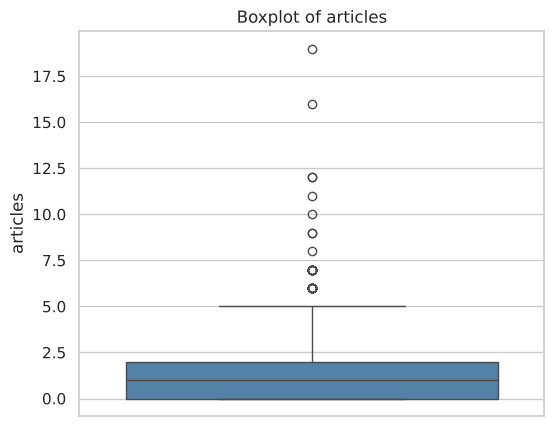

In [ ]:
num_var = "articles"     # numeric column used for univariate analysis
cat_var = "gender"       # categorical column used for univariate analysis

plt.figure(figsize=(6, 5))
sns.boxplot(y=df[num_var], color="steelblue")
plt.title(f"Boxplot of {num_var}")
plt.ylabel(num_var)
plt.show()

### 15. Identify outliers using the interquartile range method

In [ ]:
Q1 = df[num_var].quantile(0.25)
Q3 = df[num_var].quantile(0.75)
IQR_val = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR_val
upper_bound = Q3 + 1.5 * IQR_val
print("Lower bound:", lower_bound, " Upper bound:", upper_bound)

outliers = df[(df[num_var] < lower_bound) | (df[num_var] > upper_bound)]
print("Number of outliers:", len(outliers))
outliers

Lower bound: -3.0  Upper bound: 5.0
Number of outliers: 38


,rownames,articles,gender,married,kids,prestige,mentor
877,878,6.0,male,yes,0.0,4.62,8.0
878,879,6.0,female,yes,0.0,2.10,36.0
879,880,6.0,female,yes,2.0,1.86,38.0
880,881,6.0,male,yes,0.0,4.34,9.0
881,882,6.0,female,yes,0.0,4.29,24.0
882,883,6.0,male,yes,2.0,2.51,11.0
883,884,6.0,male,yes,1.0,2.96,13.0
884,885,6.0,male,no,0.0,4.29,18.0
885,886,6.0,male,no,0.0,3.40,14.0
886,887,6.0,female,no,0.0,4.54,12.0


### 16. Remove extreme outliers from the dataset

In [ ]:
df_no_outliers = df[(df[num_var] >= lower_bound) & (df[num_var] <= upper_bound)]
print(df.shape, df_no_outliers.shape)

(915, 7) (877, 7)


### 17. Create a histogram for a numerical variable and interpret its distribution

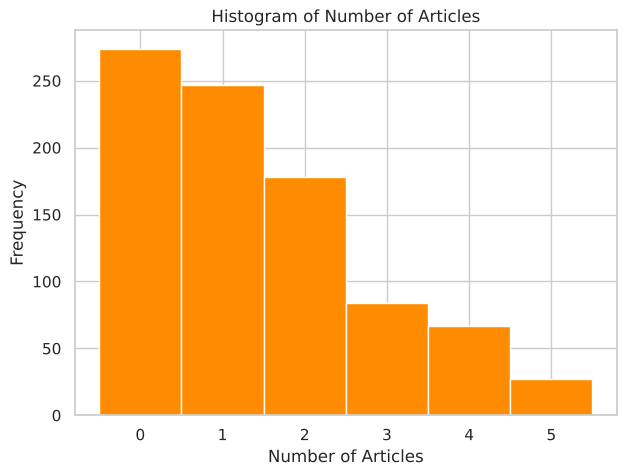

In [ ]:
plt.figure(figsize=(7, 5))
plt.hist(df_no_outliers[num_var], bins=np.arange(-0.5, df_no_outliers[num_var].max() + 1.5, 1),
         color="darkorange", edgecolor="white")
plt.title("Histogram of Number of Articles")
plt.xlabel("Number of Articles"); plt.ylabel("Frequency")
plt.show()

**Interpretation:** The distribution of articles is strongly **right-skewed** – most students published 0–2 articles, and the frequency drops steadily as the number of articles increases.

### 18. Add a density curve to the histogram

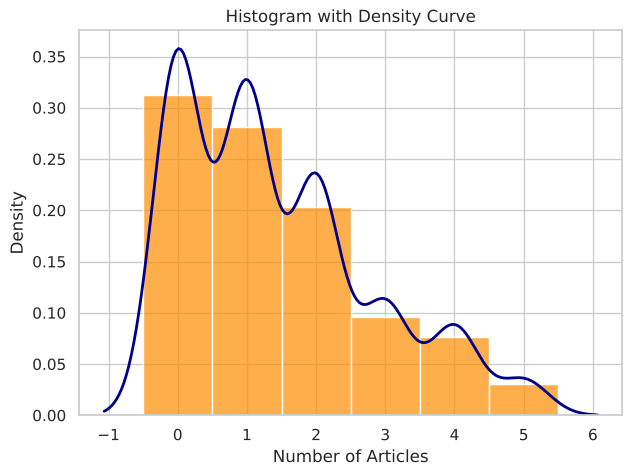

In [ ]:
plt.figure(figsize=(7, 5))
sns.histplot(df_no_outliers[num_var], stat="density", discrete=True,
             color="darkorange", alpha=0.7)
sns.kdeplot(df_no_outliers[num_var], color="darkblue", linewidth=2)
plt.title("Histogram with Density Curve")
plt.xlabel("Number of Articles"); plt.ylabel("Density")
plt.show()

### 19. Create a violin plot

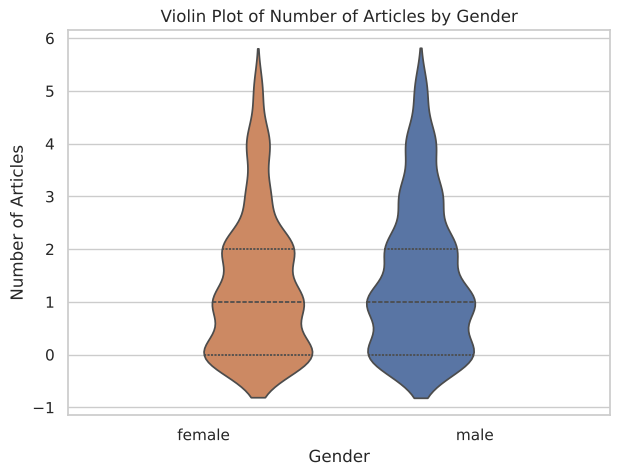

In [ ]:
plt.figure(figsize=(7, 5))
sns.violinplot(data=df_no_outliers, x=cat_var, y=num_var, hue=cat_var,
               inner="quartile", legend=False)
plt.title("Violin Plot of Number of Articles by Gender")
plt.xlabel("Gender"); plt.ylabel("Number of Articles")
plt.show()

### 20. Create a dot plot for a small numerical dataset

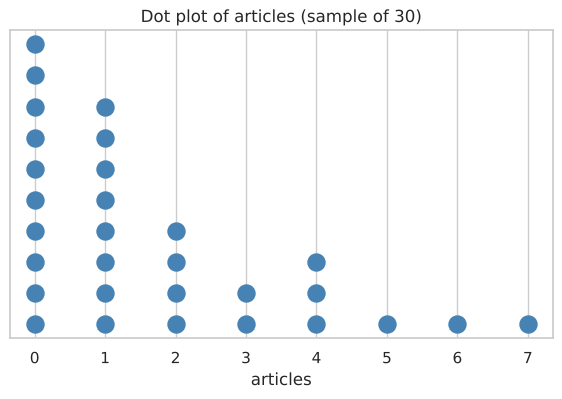

In [ ]:
small_df = df.sample(n=min(30, len(df)), random_state=1)    # small subset
vals = small_df[num_var].sort_values()
stack = vals.groupby(vals).cumcount() + 1                   # stack identical values

plt.figure(figsize=(7, 4))
plt.scatter(vals, stack, s=150, color="steelblue")
plt.title(f"Dot plot of {num_var} (sample of 30)")
plt.xlabel(num_var); plt.yticks([])
plt.show()

### 21. Create a frequency table for a categorical variable

In [ ]:
freq_table = df[cat_var].value_counts().rename_axis(cat_var).reset_index(name="Frequency")
freq_table

,gender,Frequency
0,male,497
1,female,418


### 22. Calculate the proportion and percentage of each category

In [ ]:
freq_table["Proportion"] = freq_table["Frequency"] / freq_table["Frequency"].sum()
freq_table["Percentage"] = (freq_table["Proportion"] * 100).round(2)
freq_table

,gender,Frequency,Proportion,Percentage
0,male,497,0.543169,54.32
1,female,418,0.456831,45.68


### 23. Create a bar chart showing the frequency of each category

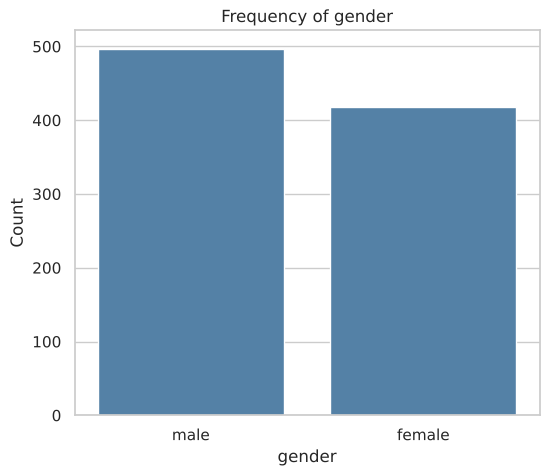

In [ ]:
order = df[cat_var].value_counts().index        # fct_infreq -> most frequent first
plt.figure(figsize=(6, 5))
sns.countplot(data=df, x=cat_var, order=order, color="steelblue")
plt.title(f"Frequency of {cat_var}")
plt.xlabel(cat_var); plt.ylabel("Count")
plt.show()

### 24. Create a horizontal bar chart for a variable with several categories

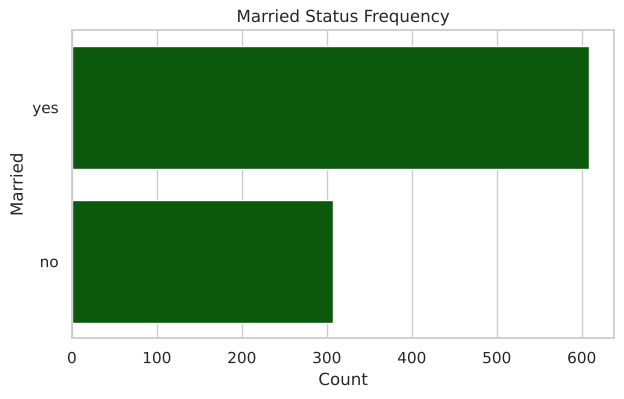

In [ ]:
plt.figure(figsize=(7, 4))
sns.countplot(data=df, y="married", order=df["married"].value_counts().index, color="darkgreen")
plt.title("Married Status Frequency")
plt.xlabel("Count"); plt.ylabel("Married")
plt.show()

### 25. Create a percentage bar chart instead of a frequency bar chart

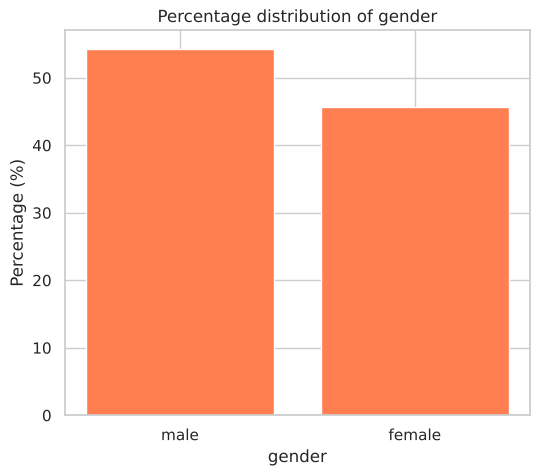

In [ ]:
ft = freq_table.sort_values("Percentage", ascending=False)
plt.figure(figsize=(6, 5))
plt.bar(ft[cat_var].astype(str), ft["Percentage"], color="coral")
plt.title(f"Percentage distribution of {cat_var}")
plt.xlabel(cat_var); plt.ylabel("Percentage (%)")
plt.show()

### 26. Create a pie chart for a categorical variable with a small number of categories

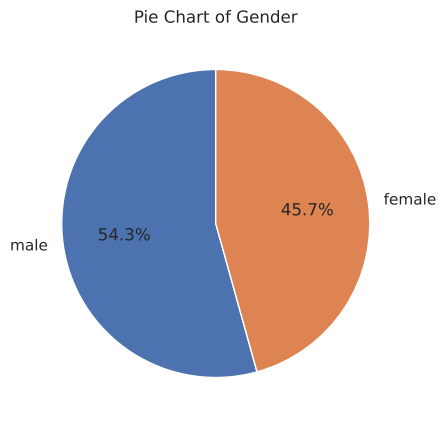

In [ ]:
plt.figure(figsize=(5, 5))
plt.pie(freq_table["Percentage"], labels=freq_table[cat_var].astype(str),
        autopct="%1.1f%%", startangle=90, wedgeprops={"edgecolor": "white"})
plt.title("Pie Chart of Gender")
plt.show()

### 27. Create a lollipop chart for categorical frequencies

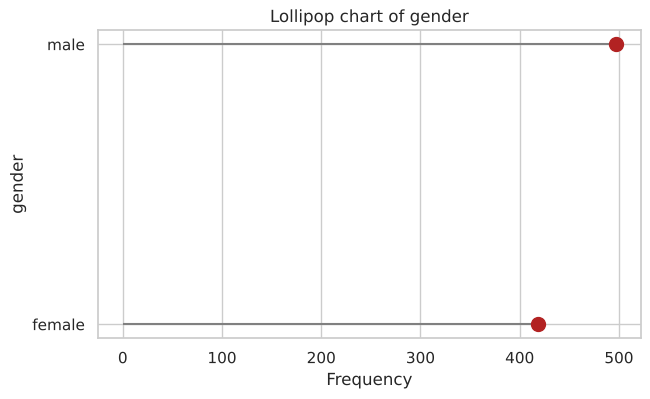

In [ ]:
ft = freq_table.sort_values("Frequency")
plt.figure(figsize=(7, 4))
plt.hlines(y=ft[cat_var].astype(str), xmin=0, xmax=ft["Frequency"], color="grey")
plt.plot(ft["Frequency"], ft[cat_var].astype(str), "o", markersize=10, color="firebrick")
plt.title(f"Lollipop chart of {cat_var}")
plt.xlabel("Frequency"); plt.ylabel(cat_var)
plt.show()

### 28. Create a dot chart

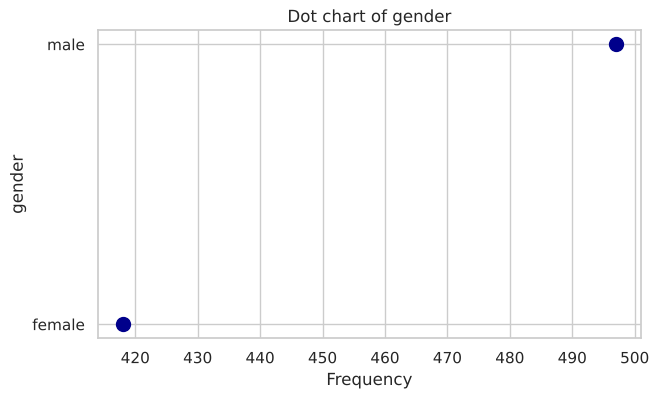

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(ft["Frequency"], ft[cat_var].astype(str), "o", markersize=10, color="darkblue")
plt.title(f"Dot chart of {cat_var}")
plt.xlabel("Frequency"); plt.ylabel(cat_var)
plt.show()

### 29. Create a density plot

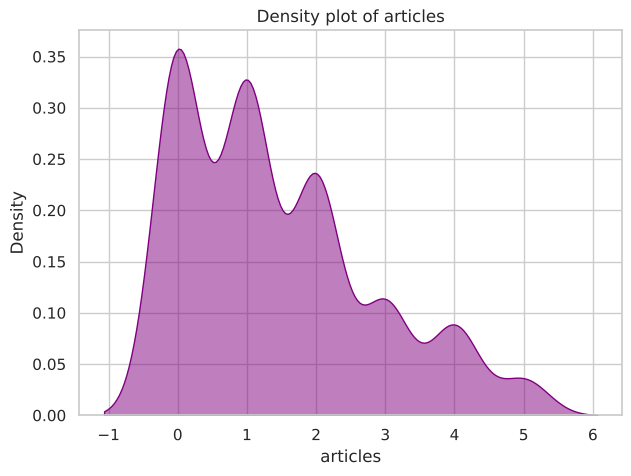

In [ ]:
plt.figure(figsize=(7, 5))
sns.kdeplot(df_no_outliers[num_var], fill=True, color="purple", alpha=0.5)
plt.title(f"Density plot of {num_var}")
plt.xlabel(num_var); plt.ylabel("Density")
plt.show()

### 30. Use facets (facet_wrap) to display the distribution of one variable across different groups

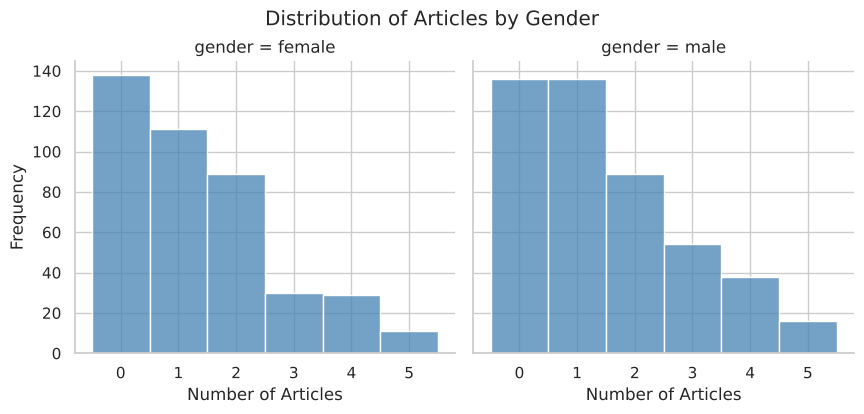

In [ ]:
group_var = cat_var
g = sns.displot(df_no_outliers, x=num_var, col=group_var, discrete=True,
                color="steelblue", height=4, aspect=1.1)
g.figure.suptitle(f"Distribution of Articles by Gender", y=1.03)
g.set_axis_labels("Number of Articles", "Frequency")
plt.show()

**Interpretation:** Both groups are right-skewed. Females have the most students at 0 articles and drop off quickly; males have about equal numbers at 0 and 1 articles and a heavier tail at 3–5 articles, so males publish slightly more on average.

---
# DA-4 : Bivariate Analysis and Visualization
### 1. Load the dataset and perform the following bivariate analysis tasks

In [ ]:
data = pd.read_csv(CSV_PATH)
data.info()
data.head()

<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  915 non-null    int64  
 1   articles  913 non-null    float64
 2   gender    910 non-null    str    
 3   married   905 non-null    str    
 4   kids      909 non-null    float64
 5   prestige  904 non-null    float64
 6   mentor    913 non-null    float64
dtypes: float64(4), int64(1), str(2)
memory usage: 50.2 KB


,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0


### 2. Two categorical variables: contingency table, (a) simple stacked bar plot (base), (b) stacked bar plot (ggplot-style)

Contingency Table (Gender vs Married):
married   no  yes
gender           
female   193  221
male     111  375


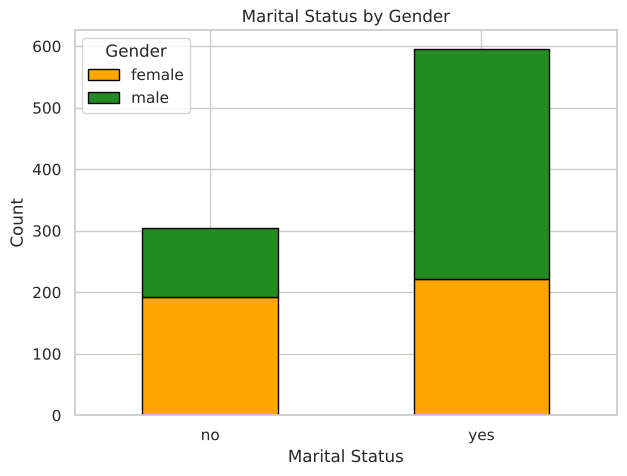

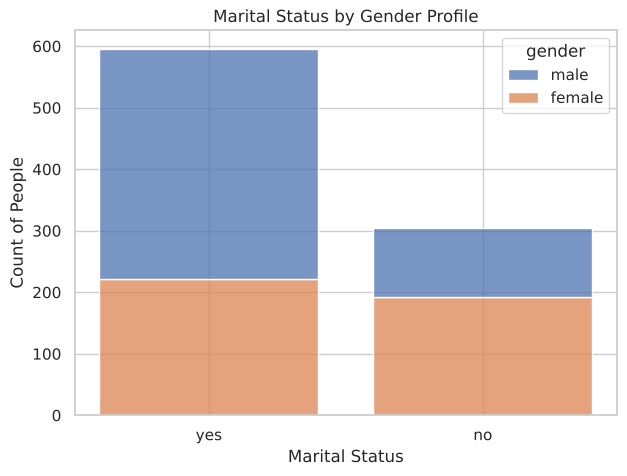

In [ ]:
cont_table = pd.crosstab(data["gender"], data["married"])
print("Contingency Table (Gender vs Married):")
print(cont_table)

# a. Simple stacked bar plot (like base R barplot)
cont_table.T.plot(kind="bar", stacked=True, color=["orange", "forestgreen"],
                  figsize=(7, 5), edgecolor="black", rot=0)
plt.title("Marital Status by Gender")
plt.xlabel("Marital Status"); plt.ylabel("Count")
plt.legend(title="Gender")
plt.show()

# b. Stacked bar plot (seaborn / ggplot style)
plt.figure(figsize=(7, 5))
sns.histplot(data=data.dropna(subset=["gender", "married"]), x="married", hue="gender",
             multiple="stack", discrete=True, shrink=0.8)
plt.title("Marital Status by Gender Profile")
plt.xlabel("Marital Status"); plt.ylabel("Count of People")
plt.show()

### 3. Grouped / side-by-side bar plot to compare frequency distributions

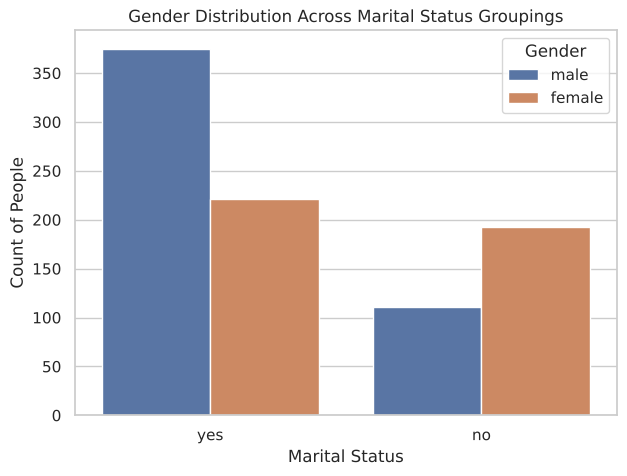

In [ ]:
plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="married", hue="gender")
plt.title("Gender Distribution Across Marital Status Groupings")
plt.xlabel("Marital Status"); plt.ylabel("Count of People")
plt.legend(title="Gender")
plt.show()

### 4. Two numerical variables: scatter plot to analyse the relationship

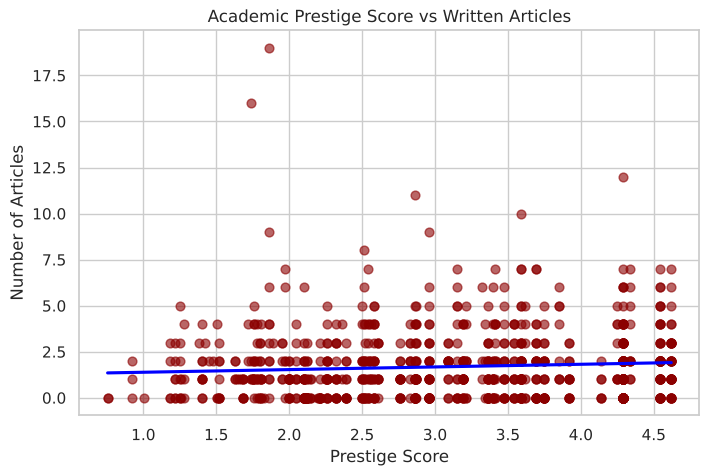

In [ ]:
plt.figure(figsize=(8, 5))
sns.regplot(data=data, x="prestige", y="articles", ci=None,
            scatter_kws={"color": "darkred", "alpha": 0.6, "s": 40},
            line_kws={"color": "blue"})
plt.title("Academic Prestige Score vs Written Articles")
plt.xlabel("Prestige Score"); plt.ylabel("Number of Articles")
plt.show()

### 5. Line plot to visualize relationship / trend

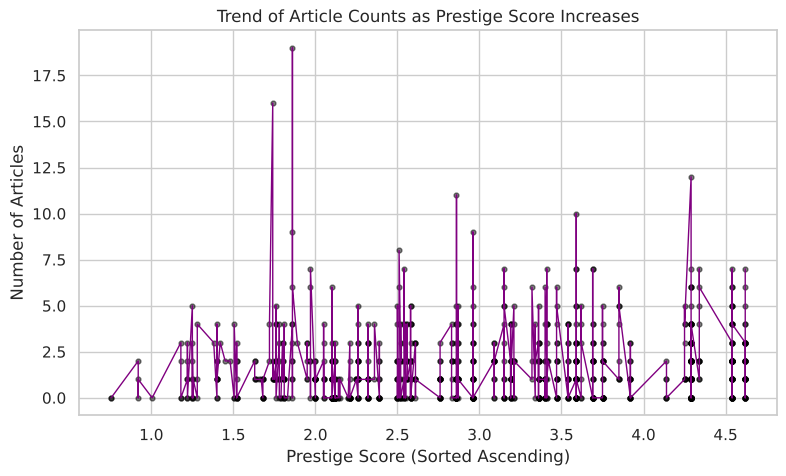

In [ ]:
data_sorted = data.sort_values("prestige")

plt.figure(figsize=(9, 5))
plt.plot(data_sorted["prestige"], data_sorted["articles"], color="purple", linewidth=1)
plt.scatter(data_sorted["prestige"], data_sorted["articles"], color="black", alpha=0.5, s=12)
plt.title("Trend of Article Counts as Prestige Score Increases")
plt.xlabel("Prestige Score (Sorted Ascending)"); plt.ylabel("Number of Articles")
plt.show()

### 6. Heatmap to represent the relationship among numerical variables

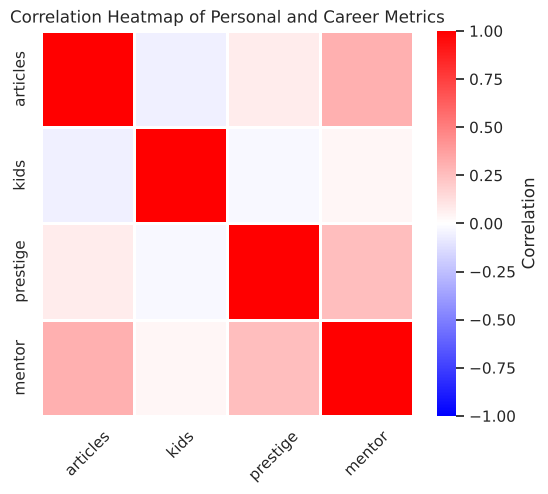

In [ ]:
num_vars = data[["articles", "kids", "prestige", "mentor"]]
cor_matrix = num_vars.dropna().corr()        # use = "complete.obs"

plt.figure(figsize=(6, 5))
sns.heatmap(cor_matrix, cmap="bwr", vmin=-1, vmax=1, center=0,
            linewidths=1, linecolor="white", cbar_kws={"label": "Correlation"})
plt.title("Correlation Heatmap of Personal and Career Metrics")
plt.xticks(rotation=45)
plt.show()

### 7. Bar chart to compare the values between two variables

   gender  variable     value
0  female  articles  1.472422
1    male  articles  1.879837
2  female    mentor  7.889688
3    male    mentor  9.574338


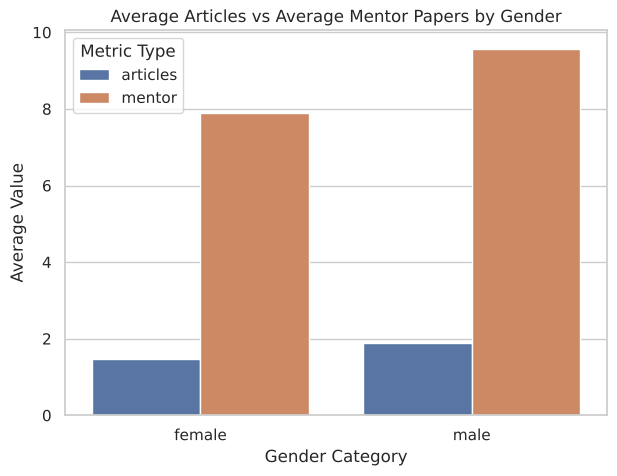

In [ ]:
agg_data = data.groupby("gender")[["articles", "mentor"]].mean().reset_index()
agg_melted = agg_data.melt(id_vars="gender", var_name="variable", value_name="value")
print(agg_melted)

plt.figure(figsize=(7, 5))
sns.barplot(data=agg_melted, x="gender", y="value", hue="variable")
plt.title("Average Articles vs Average Mentor Papers by Gender")
plt.xlabel("Gender Category"); plt.ylabel("Average Value")
plt.legend(title="Metric Type")
plt.show()

### 8. Density plot to compare a numerical variable across categories

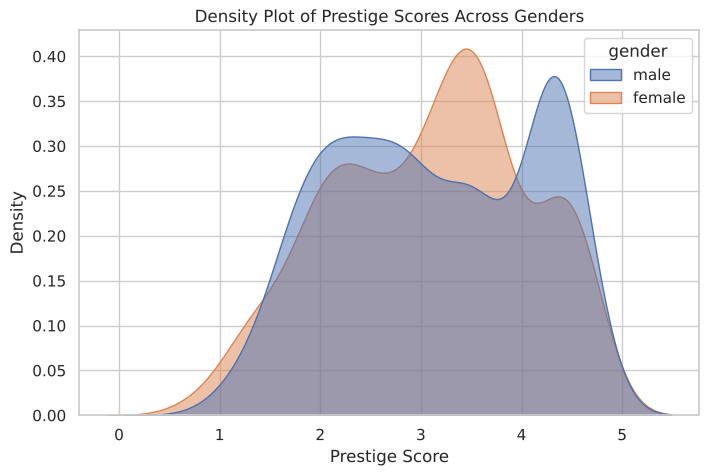

In [ ]:
plt.figure(figsize=(8, 5))
sns.kdeplot(data=data.dropna(subset=["gender"]), x="prestige", hue="gender",
            fill=True, alpha=0.5, common_norm=False)
plt.title("Density Plot of Prestige Scores Across Genders")
plt.xlabel("Prestige Score"); plt.ylabel("Density")
plt.show()

### 9. Box plot to compare a numerical variable across groups

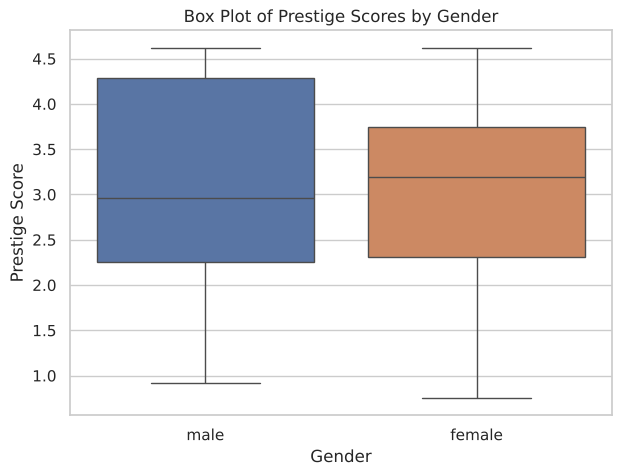

In [ ]:
plt.figure(figsize=(7, 5))
sns.boxplot(data=data.dropna(subset=["gender"]), x="gender", y="prestige", hue="gender")
plt.title("Box Plot of Prestige Scores by Gender")
plt.xlabel("Gender"); plt.ylabel("Prestige Score")
plt.show()

### 10. Violin plot to visualize the distribution and density across categories

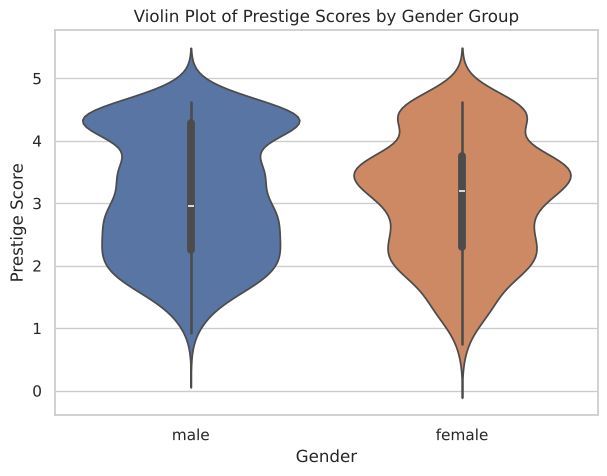

In [ ]:
plt.figure(figsize=(7, 5))
sns.violinplot(data=data.dropna(subset=["gender"]), x="gender", y="prestige",
               hue="gender", cut=3)      # cut=3 ~ trim = FALSE
plt.title("Violin Plot of Prestige Scores by Gender Group")
plt.xlabel("Gender"); plt.ylabel("Prestige Score")
plt.show()

### 11. Combine a violin plot and a box plot in a single graph

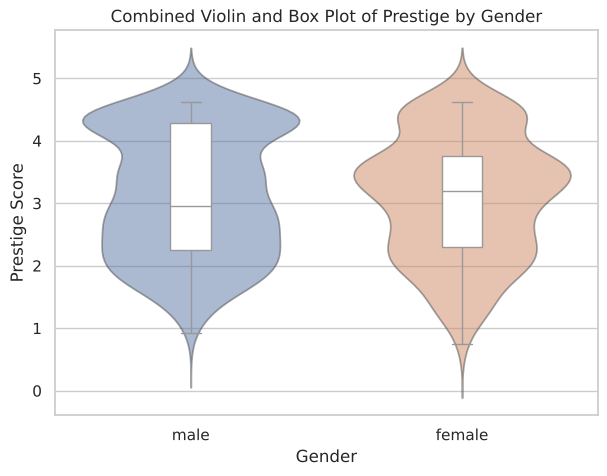

In [ ]:
d = data.dropna(subset=["gender"])
plt.figure(figsize=(7, 5))
sns.violinplot(data=d, x="gender", y="prestige", hue="gender", cut=3, alpha=0.5, inner=None)
sns.boxplot(data=d, x="gender", y="prestige", width=0.15, color="white",
            flierprops={"markerfacecolor": "red"})
plt.title("Combined Violin and Box Plot of Prestige by Gender")
plt.xlabel("Gender"); plt.ylabel("Prestige Score")
plt.show()

### 12. Correlation matrix and correlogram

Rounded Correlation Matrix:
          articles  kids  prestige  mentor
articles      1.00 -0.06      0.07    0.31
kids         -0.06  1.00     -0.03    0.04
prestige      0.07 -0.03      1.00    0.26
mentor        0.31  0.04      0.26    1.00


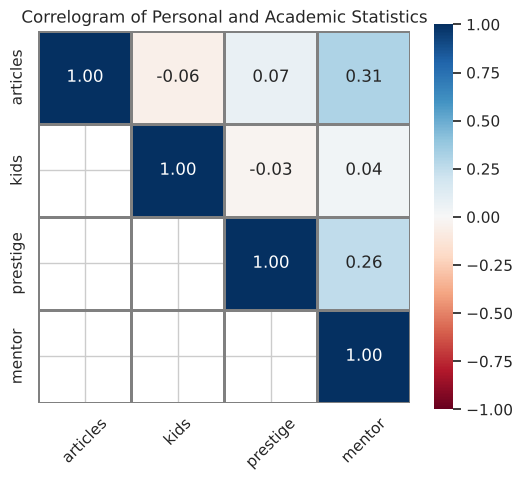

In [ ]:
num_vars2 = data[["articles", "kids", "prestige", "mentor"]]
cor_matrix2 = num_vars2.dropna().corr()
print("Rounded Correlation Matrix:")
print(cor_matrix2.round(2))

mask = np.tril(np.ones_like(cor_matrix2, dtype=bool), k=-1)   # type = "upper"
plt.figure(figsize=(6, 5))
sns.heatmap(cor_matrix2, mask=mask, annot=True, fmt=".2f", cmap="RdBu",
            vmin=-1, vmax=1, square=True, linewidths=1, linecolor="grey")
plt.title("Correlogram of Personal and Academic Statistics")
plt.xticks(rotation=45)
plt.show()

### 13. Provide suitable titles, axis labels, legends and graphical parameters for all the plots generated

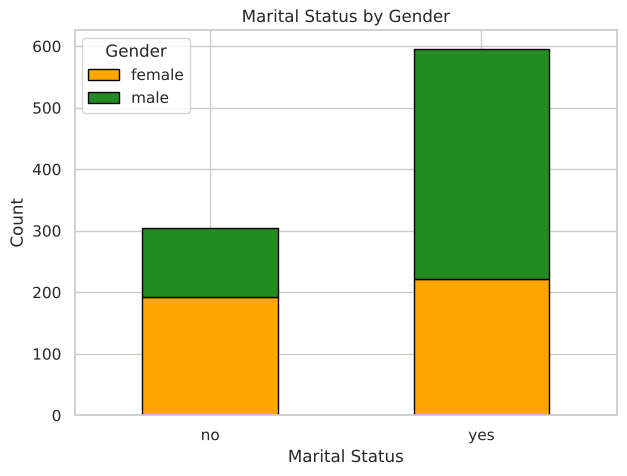

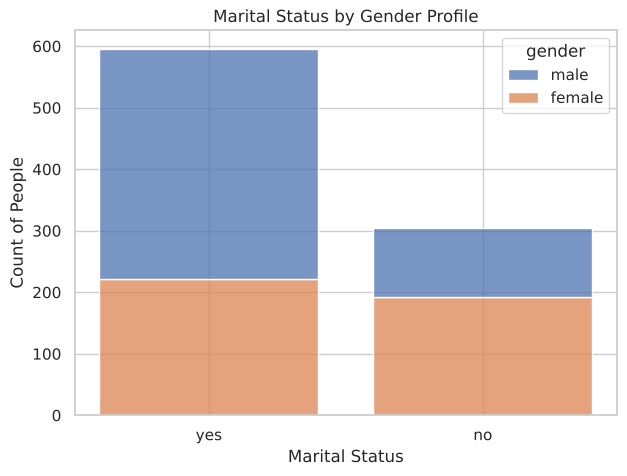

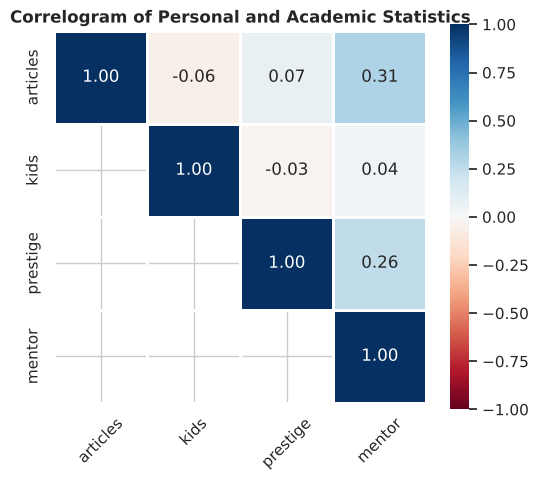

In [ ]:
# 1. Simple (base-style) stacked bar plot
ax = cont_table.T.plot(kind="bar", stacked=True,
                       color=["orange", "forestgreen"],      # colour parameter
                       figsize=(7, 5), rot=0, edgecolor="black")
ax.set_title("Marital Status by Gender")                     # title
ax.set_xlabel("Marital Status")                              # x-axis label
ax.set_ylabel("Count")                                       # y-axis label
ax.legend(title="Gender")                                    # legend
plt.show()

# 2. seaborn plots (Q2b - Q11) all follow this labelling pattern
plt.figure(figsize=(7, 5))
sns.histplot(data=data.dropna(subset=["gender", "married"]), x="married",
             hue="gender", multiple="stack", discrete=True, shrink=0.8)
plt.title("Marital Status by Gender Profile")                # title
plt.xlabel("Marital Status")                                 # x-axis label
plt.ylabel("Count of People")                                # y-axis label (legend title = hue name)
plt.show()

# 3. Correlogram – graphical parameters
plt.figure(figsize=(6, 5))
sns.heatmap(cor_matrix2, mask=mask,
            annot=True, fmt=".2f",                           # correlation coefficients displayed
            cmap="RdBu", vmin=-1, vmax=1,                    # colour scale
            square=True, linewidths=1)
plt.title("Correlogram of Personal and Academic Statistics", fontweight="bold")
plt.xticks(rotation=45)                                      # text label rotation
plt.show()

---
# DA-5 : Multivariate Visualization
### 1. Load the dataset, examine it and identify the numerical and categorical variables

In [ ]:
data = pd.read_csv(CSV_PATH)
display(data.head())
data.info()
display(data.describe(include="all"))
print(data.columns.tolist())

num_vars = data.select_dtypes(include="number")
print("Numerical variables  :", num_vars.columns.tolist())
cat_vars = data.select_dtypes(exclude="number")
print("Categorical variables:", cat_vars.columns.tolist())

,rownames,articles,gender,married,kids,prestige,mentor
0,1,0.0,male,yes,0.0,2.52,7.0
1,2,0.0,female,no,0.0,2.05,6.0
2,3,0.0,female,no,0.0,3.75,6.0
3,4,0.0,male,yes,1.0,1.18,3.0
4,5,0.0,female,no,0.0,3.75,26.0


<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   rownames  915 non-null    int64  
 1   articles  913 non-null    float64
 2   gender    910 non-null    str    
 3   married   905 non-null    str    
 4   kids      909 non-null    float64
 5   prestige  904 non-null    float64
 6   mentor    913 non-null    float64
dtypes: float64(4), int64(1), str(2)
memory usage: 50.2 KB


,rownames,articles,gender,married,kids,prestige,mentor
count,915.000000,913.000000,910,905,909.000000,904.000000,913.000000
unique,NaN,NaN,2,2,NaN,NaN,NaN
top,NaN,NaN,male,yes,NaN,NaN,NaN
freq,NaN,NaN,492,598,NaN,NaN,NaN
mean,458.000000,1.695509,NaN,NaN,0.492849,3.111753,8.782037
std,264.282046,1.927226,NaN,NaN,0.764870,0.981712,9.488545
min,1.000000,0.000000,NaN,NaN,0.000000,0.755000,0.000000
25%,229.500000,0.000000,NaN,NaN,0.000000,2.260000,3.000000
50%,458.000000,1.000000,NaN,NaN,0.000000,3.190000,6.000000
75%,686.500000,2.000000,NaN,NaN,1.000000,3.920000,12.000000


['rownames', 'articles', 'gender', 'married', 'kids', 'prestige', 'mentor']
Numerical variables  : ['rownames', 'articles', 'kids', 'prestige', 'mentor']
Categorical variables: ['gender', 'married']


### 2. Scatter plot with three variables (X, Y numerical, third variable = colour)

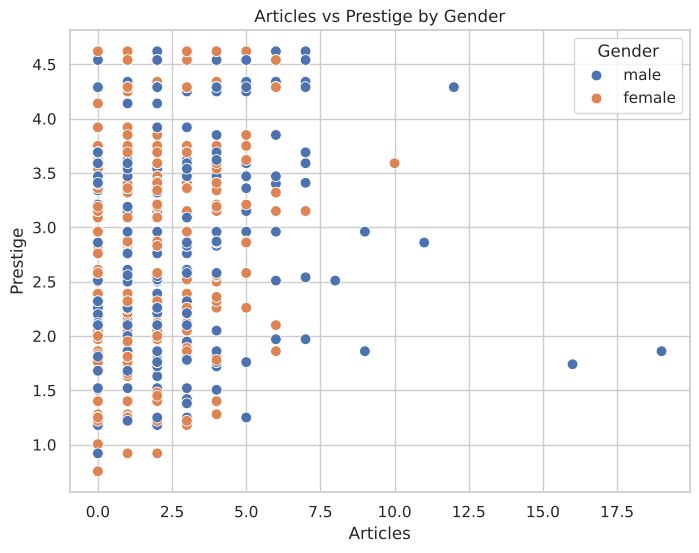

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x="articles", y="prestige", hue="gender", s=60)
plt.title("Articles vs Prestige by Gender")
plt.xlabel("Articles"); plt.ylabel("Prestige")
plt.legend(title="Gender")
plt.show()

### 3. Scatter plot with four variables (colour + shape)

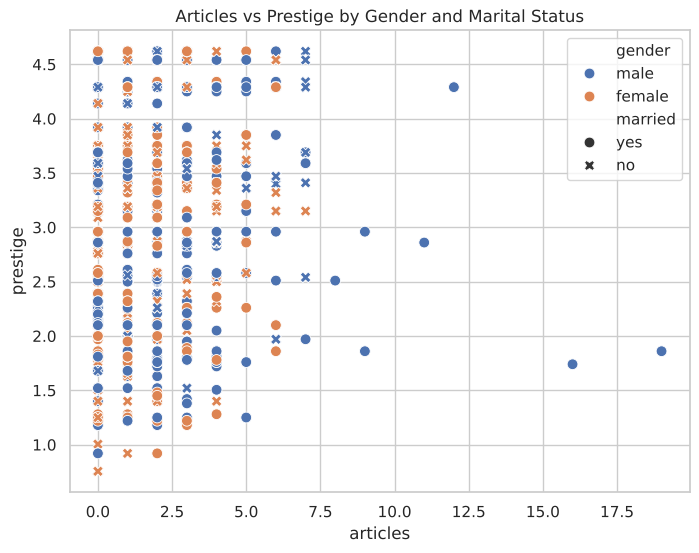

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x="articles", y="prestige", hue="gender", style="married", s=60)
plt.title("Articles vs Prestige by Gender and Marital Status")
plt.show()

### 4. Scatter plot with four variables (colour + point size for a numerical variable)

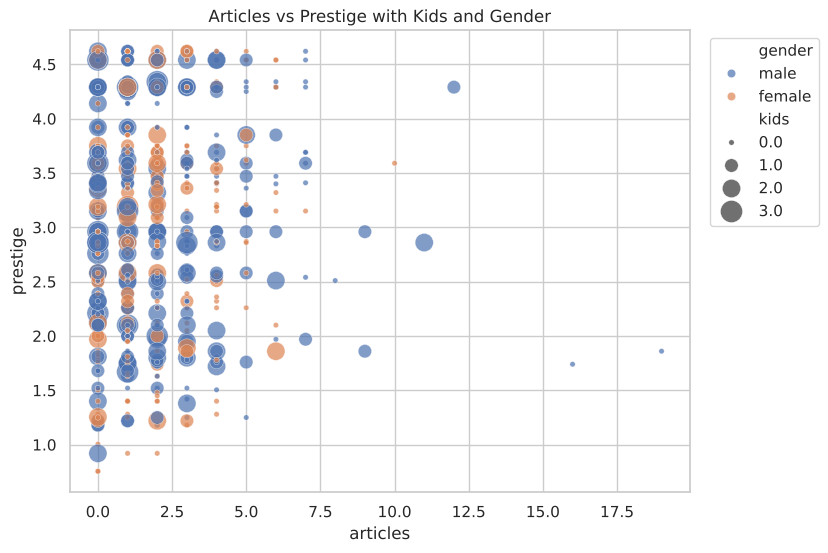

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x="articles", y="prestige", hue="gender",
                size="kids", sizes=(15, 250), alpha=0.7)
plt.title("Articles vs Prestige with Kids and Gender")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### 5. Bubble plot with three numerical variables (third = bubble size)

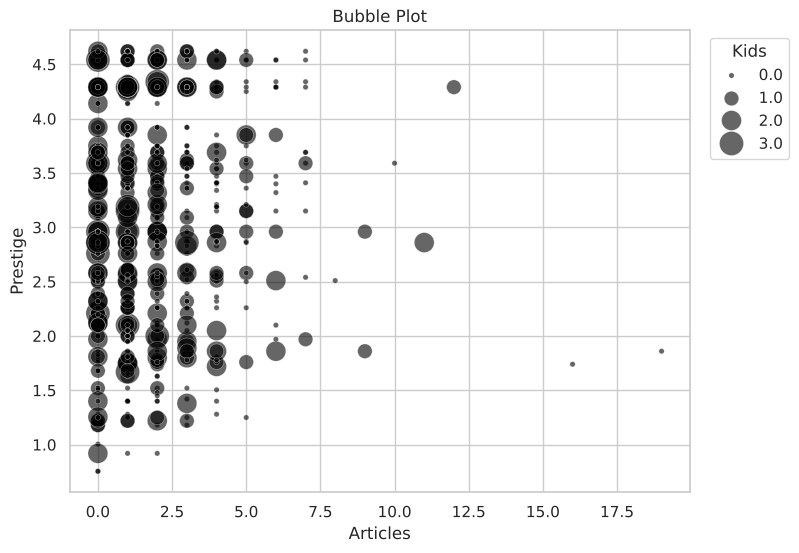

In [ ]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=data, x="articles", y="prestige", size="kids",
                sizes=(15, 300), alpha=0.6, color="black")
plt.title("Bubble Plot")
plt.xlabel("Articles"); plt.ylabel("Prestige")
plt.legend(title="Kids", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

### 6. Subplots using facet_wrap() with an appropriate categorical variable

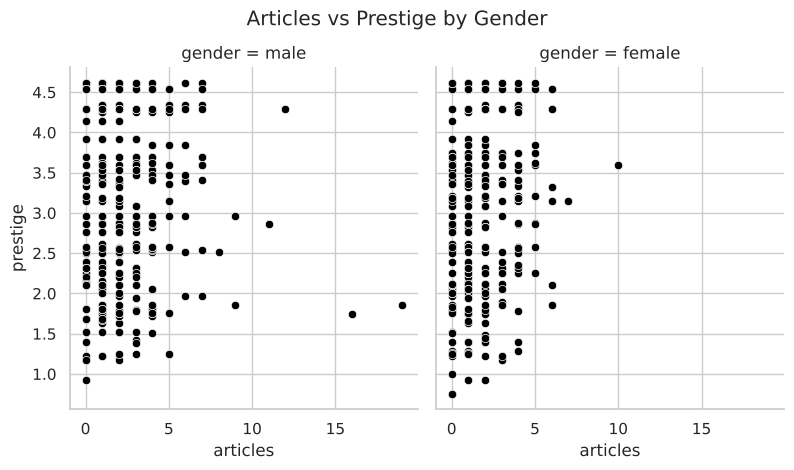

In [ ]:
g = sns.relplot(data=data, x="articles", y="prestige", col="gender", color="black",
                height=4.5, aspect=0.9)
g.figure.suptitle("Articles vs Prestige by Gender", y=1.04)
plt.show()

### 7. Subplots using facet_grid() with two categorical variables (rows × columns)

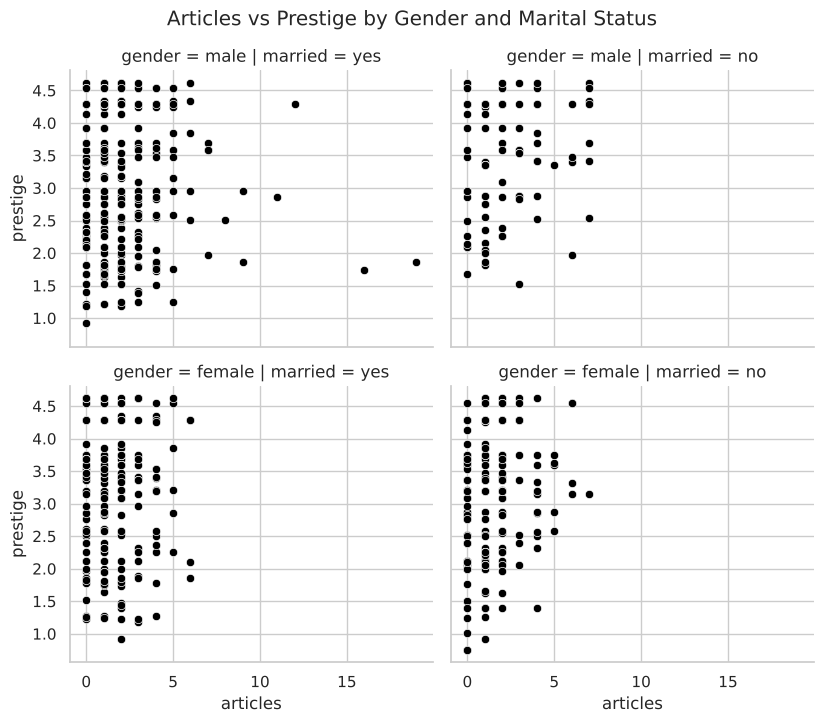

In [ ]:
g = sns.relplot(data=data, x="articles", y="prestige", row="gender", col="married",
                color="black", height=3.5, aspect=1.2)
g.figure.suptitle("Articles vs Prestige by Gender and Marital Status", y=1.03)
plt.show()

**Comparison:** In every gender × marital-status panel, most students sit at low article counts (0–5) across the whole prestige range. Married males show the widest spread and contain the extreme high-publication outliers (10–19 articles); females (married or not) are more concentrated at low article counts.

### 8. Pairs plot with at least four numerical variables – relationships and correlations

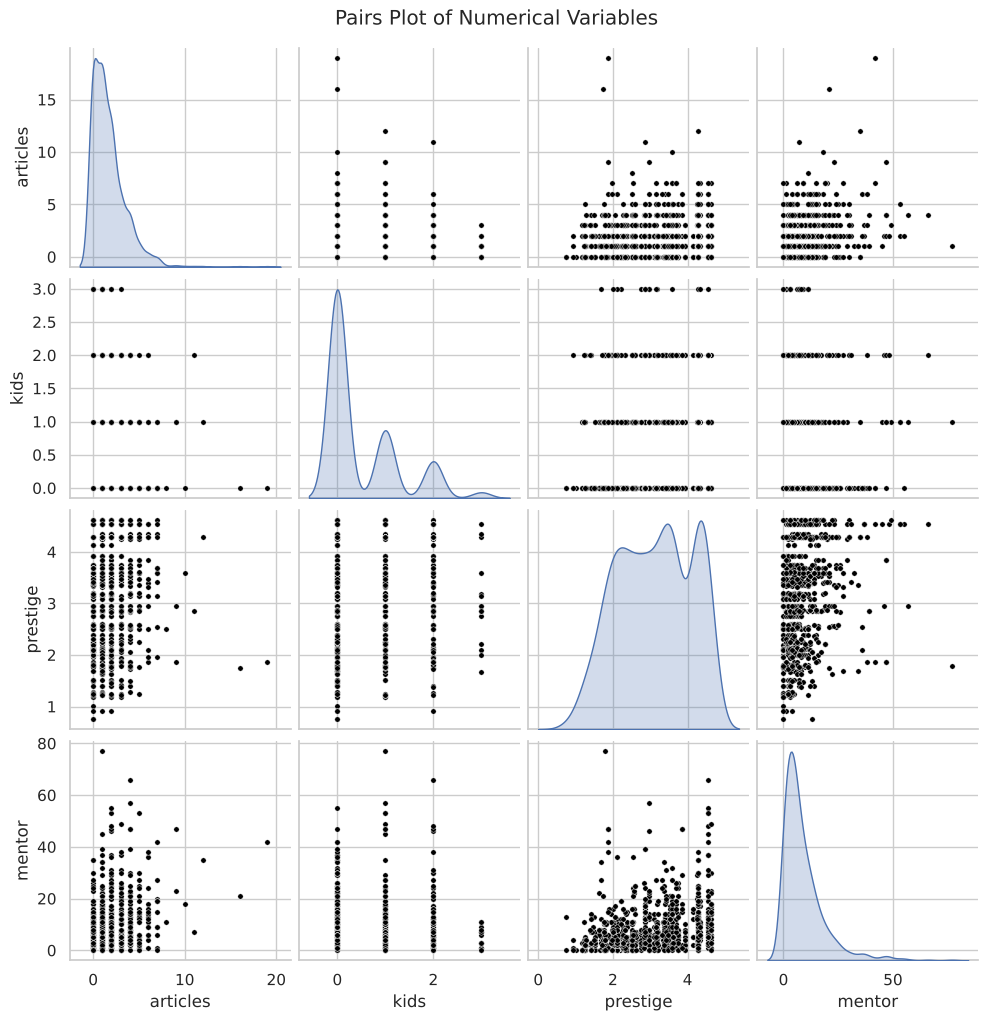

Correlation matrix:
          articles   kids  prestige  mentor
articles     1.000 -0.048     0.075   0.305
kids        -0.048  1.000    -0.030   0.038
prestige     0.075 -0.030     1.000   0.255
mentor       0.305  0.038     0.255   1.000


In [ ]:
cols = ["articles", "kids", "prestige", "mentor"]
sns.pairplot(data[cols].dropna(), diag_kind="kde", plot_kws={"s": 15, "color": "black"})
plt.suptitle("Pairs Plot of Numerical Variables", y=1.02)
plt.show()

print("Correlation matrix:")
print(data[cols].corr().round(3))

**Observations:** articles–mentor (≈0.31) and prestige–mentor (≈0.26) show weak positive correlations; kids is almost uncorrelated with the other variables. articles, kids and mentor are right-skewed.

### 9. Parallel coordinate plot with at least four numerical variables, grouped by a categorical variable

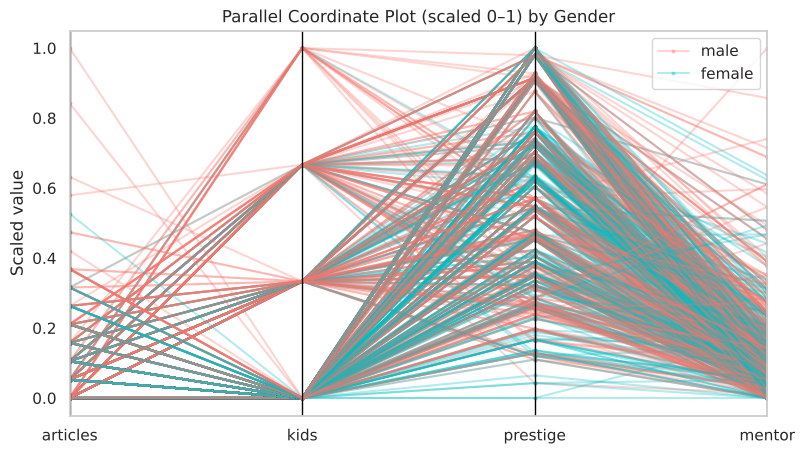

In [ ]:
from pandas.plotting import parallel_coordinates

pc = data[cols + ["gender"]].dropna().copy()
pc[cols] = (pc[cols] - pc[cols].min()) / (pc[cols].max() - pc[cols].min())   # scale = "uniminmax"

plt.figure(figsize=(9, 5))
parallel_coordinates(pc, "gender", color=["#F8766D", "#00BFC4"], alpha=0.3, marker="o", markersize=2)
plt.title("Parallel Coordinate Plot (scaled 0–1) by Gender")
plt.ylabel("Scaled value")
plt.show()

---
# DA-6 : Time Series Analysis (AirPassengers)
`AirPassengers` is built into R; in Python the same 144 monthly values (1949–1960) are entered below.
### 1. Load the AirPassengers dataset

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX

air_values = [
    112, 118, 132, 129, 121, 135, 148, 148, 136, 119, 104, 118,   # 1949
    115, 126, 141, 135, 125, 149, 170, 170, 158, 133, 114, 140,   # 1950
    145, 150, 178, 163, 172, 178, 199, 199, 184, 162, 146, 166,   # 1951
    171, 180, 193, 181, 183, 218, 230, 242, 209, 191, 172, 194,   # 1952
    196, 196, 236, 235, 229, 243, 264, 272, 237, 211, 180, 201,   # 1953
    204, 188, 235, 227, 234, 264, 302, 293, 259, 229, 203, 229,   # 1954
    242, 233, 267, 269, 270, 315, 364, 347, 312, 274, 237, 278,   # 1955
    284, 277, 317, 313, 318, 374, 413, 405, 355, 306, 271, 306,   # 1956
    315, 301, 356, 348, 355, 422, 465, 467, 404, 347, 305, 336,   # 1957
    340, 318, 362, 348, 363, 435, 491, 505, 404, 359, 310, 337,   # 1958
    360, 342, 406, 396, 420, 472, 548, 559, 463, 407, 362, 405,   # 1959
    417, 391, 419, 461, 472, 535, 622, 606, 508, 461, 390, 432,   # 1960
]
AirPassengers = pd.Series(air_values,
                          index=pd.date_range("1949-01-01", periods=144, freq="MS"),
                          name="Passengers")
AirPassengers.head()

1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

### 2. Explore the first five and last five observations

In [ ]:
display(AirPassengers.head(5))
display(AirPassengers.tail(5))

1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
Freq: MS, Name: Passengers, dtype: int64

1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Freq: MS, Name: Passengers, dtype: int64

### 3. Identify the starting and ending time periods (start, end)

In [ ]:
print("Start:", AirPassengers.index[0].year, AirPassengers.index[0].month)
print("End  :", AirPassengers.index[-1].year, AirPassengers.index[-1].month)

Start: 1949 1
End  : 1960 12


### 4. Determine the frequency and time-series characteristics (frequency, class)

In [ ]:
print("Frequency (observations per year):", 12)
print("Pandas frequency code:", AirPassengers.index.freqstr, "(monthly)")
print("Class:", type(AirPassengers))

Frequency (observations per year): 12
Pandas frequency code: MS (monthly)
Class: <class 'pandas.Series'>


### 5. Visualize the monthly passenger trend over the entire period

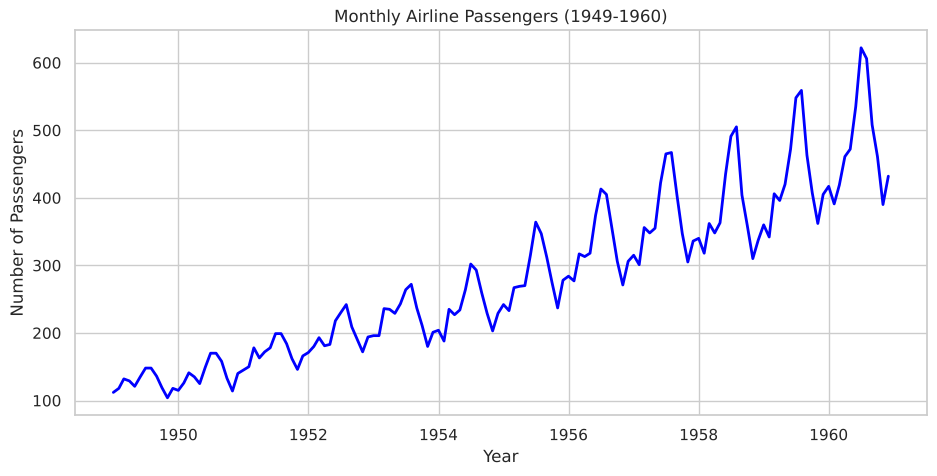

In [ ]:
plt.figure(figsize=(11, 5))
plt.plot(AirPassengers, color="blue", linewidth=2)
plt.title("Monthly Airline Passengers (1949-1960)")
plt.xlabel("Year"); plt.ylabel("Number of Passengers")
plt.show()

### 6. Decompose the time series into trend, seasonal and random components

In [ ]:
decomp = seasonal_decompose(AirPassengers, model="multiplicative", period=12)

### 7. Plot the decomposed components to examine the underlying patterns

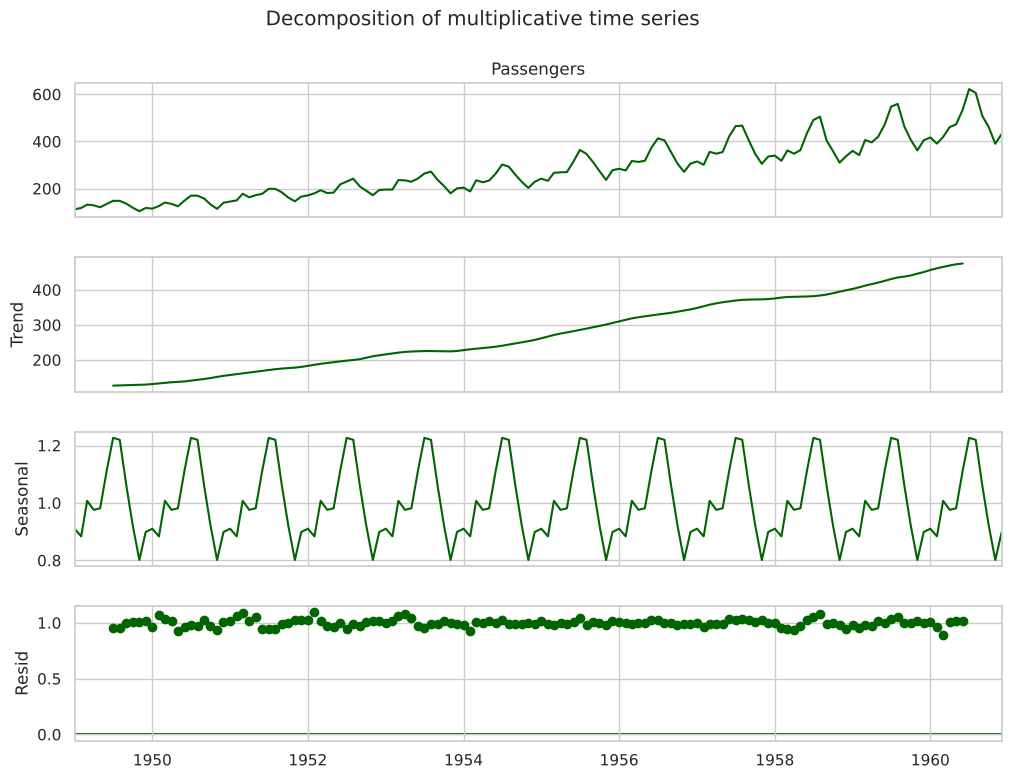

In [ ]:
fig = decomp.plot()
fig.set_size_inches(11, 8)
fig.suptitle("Decomposition of multiplicative time series", y=1.01)
for ax in fig.axes:
    for line in ax.get_lines():
        line.set_color("darkgreen")
plt.show()

### 8. Autocorrelation and partial autocorrelation (acf, pacf)

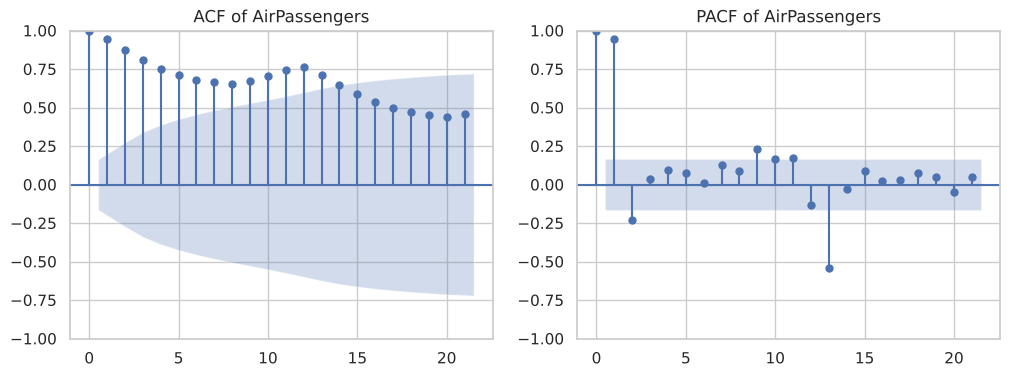

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))      # 1 row, 2 columns
plot_acf(AirPassengers, lags=21, ax=axes[0], title="ACF of AirPassengers")
plot_pacf(AirPassengers, lags=21, ax=axes[1], title="PACF of AirPassengers", method="ywm")
plt.show()

### 9. Fit an ARIMA model (seasonal ARIMA(0,1,1)(0,1,1)[12] on log data)

In [ ]:
# log transformation stabilises the increasing variance over time
log_air = np.log(AirPassengers)
arima_model = SARIMAX(log_air, order=(0, 1, 1), seasonal_order=(0, 1, 1, 12)).fit(disp=False)

### 10. Display and interpret the fitted ARIMA model parameters and summary

In [ ]:
print(arima_model.summary())
print("\nCoefficients:")
print(arima_model.params.round(4))
print("AIC:", round(arima_model.aic, 2))

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  144
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                 244.696
Date:                            Mon, 19 Oct 2026   AIC                           -483.393
Time:                                    15:48:09   BIC                           -474.767
Sample:                                01-01-1949   HQIC                          -479.888
                                     - 12-01-1960                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.4021      0.073     -5.508      0.000      -0.545      -0.259
ma.S.L12      -0.5570      0.096   

**Interpretation:** Both MA terms (ma.L1 ≈ −0.40 and seasonal ma.S.L12 ≈ −0.56) are negative and significant (p < 0.05), i.e. part of last month's and last year's shock is corrected in the current value. The small residual variance (sigma² ≈ 0.0013 on the log scale) shows a good fit.

### 11. Forecast the number of passengers for the next 12 months

In [ ]:
forecast_log = arima_model.get_forecast(steps=12)
forecast_values = np.exp(forecast_log.predicted_mean)    # back-transform from log
print("--- 12-Month Forecasted Passenger Values ---")
print(forecast_values.round(4))

--- 12-Month Forecasted Passenger Values ---
1961-01-01    450.4255
1961-02-01    425.7206
1961-03-01    479.0118
1961-04-01    492.4077
1961-05-01    509.0581
1961-06-01    583.3491
1961-07-01    670.0146
1961-08-01    667.0819
1961-09-01    558.1936
1961-10-01    497.2110
1961-11-01    429.8752
1961-12-01    477.2463
Freq: MS, Name: predicted_mean, dtype: float64


### 12. Visualize the actual and forecasted passenger values (plot, lines)

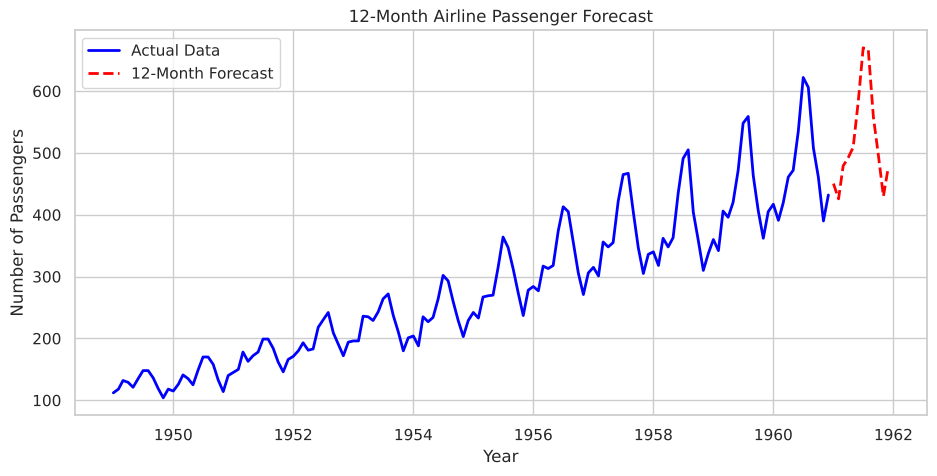

In [ ]:
plt.figure(figsize=(11, 5))
plt.plot(AirPassengers, color="blue", linewidth=2, label="Actual Data")
plt.plot(forecast_values, color="red", linewidth=2, linestyle="--", label="12-Month Forecast")
plt.title("12-Month Airline Passenger Forecast")
plt.xlabel("Year"); plt.ylabel("Number of Passengers")
plt.legend(loc="upper left")
plt.show()

---
# DA-7 : 1D, 2D and ND Analysis
### 1. Load the dataset and examine its structure

In [ ]:
data = pd.read_csv(CSV_PATH)
data = data.drop(columns="rownames")
data = data.dropna()                                    # removes NA + blank gender/married
data["gender"] = data["gender"].astype("category")
data["married"] = data["married"].astype("category")

print(data.shape)
display(data.head())
data.info()

(879, 6)


,articles,gender,married,kids,prestige,mentor
0,0.0,male,yes,0.0,2.52,7.0
1,0.0,female,no,0.0,2.05,6.0
2,0.0,female,no,0.0,3.75,6.0
3,0.0,male,yes,1.0,1.18,3.0
4,0.0,female,no,0.0,3.75,26.0


<class 'pandas.DataFrame'>
Index: 879 entries, 0 to 914
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   articles  879 non-null    float64 
 1   gender    879 non-null    category
 2   married   879 non-null    category
 3   kids      879 non-null    float64 
 4   prestige  879 non-null    float64 
 5   mentor    879 non-null    float64 
dtypes: category(2), float64(4)
memory usage: 36.1 KB


### 2. Summary statistics: Mean, Median, Min, Max, Range, Variance, SD, IQR, Skewness, Kurtosis

In [ ]:
x = data["articles"]
n = len(x)

mean_x   = x.mean()
median_x = x.median()
min_x    = x.min()
max_x    = x.max()
range_x  = max_x - min_x
var_x    = x.var()
sd_x     = x.std()
iqr_x    = x.quantile(0.75) - x.quantile(0.25)
# same formulas as R's e1071::skewness / e1071::kurtosis (default type 3)
skew_x   = stats.skew(x) * ((n - 1) / n) ** 1.5
kurt_x   = (stats.kurtosis(x) + 3) * (1 - 1 / n) ** 2 - 3

print(mean_x, median_x, min_x, max_x, range_x)
print(var_x, sd_x, iqr_x, skew_x, kurt_x)

1.6780432309442548 1.0 0.0 19.0 19.0
3.569346508379527 1.8892714226334784 2.0 2.500421666714618 13.16350525822536


### 3. Store these values in a single structured data frame and print it

In [ ]:
summary_stats = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum", "Range",
                  "Variance", "Std. Deviation", "IQR", "Skewness", "Kurtosis"],
    "Value": np.round([mean_x, median_x, min_x, max_x, range_x,
                       var_x, sd_x, iqr_x, skew_x, kurt_x], 4),
})
print(summary_stats)

        Statistic    Value
0            Mean   1.6780
1          Median   1.0000
2         Minimum   0.0000
3         Maximum  19.0000
4           Range  19.0000
5        Variance   3.5693
6  Std. Deviation   1.8893
7             IQR   2.0000
8        Skewness   2.5004
9        Kurtosis  13.1635


### 4. Frequency and relative frequency table for a categorical variable + Pie chart and Bar plot

gender
female    405
male      474
Name: count, dtype: int64
gender
female    0.4608
male      0.5392
Name: count, dtype: float64
   Gender  Frequency  Relative_Freq
0  female        405         0.4608
1    male        474         0.5392


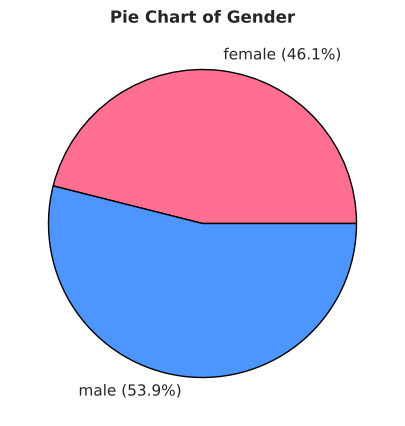

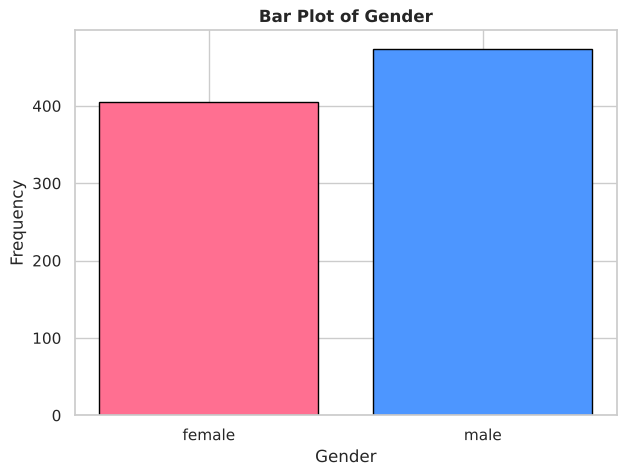

In [ ]:
freq_table = data["gender"].value_counts().sort_index()
print(freq_table)
rel_freq = freq_table / freq_table.sum()
print(rel_freq.round(4))

freq_df = pd.DataFrame({"Gender": freq_table.index,
                        "Frequency": freq_table.values,
                        "Relative_Freq": rel_freq.round(4).values})
print(freq_df)

plt.figure(figsize=(5, 5))
plt.pie(freq_table, colors=["#FF6F91", "#4D96FF"],
        labels=[f"{g} ({p:.1f}%)" for g, p in zip(freq_table.index, rel_freq * 100)],
        wedgeprops={"edgecolor": "black"})
plt.title("Pie Chart of Gender", fontweight="bold")
plt.show()

plt.figure(figsize=(7, 5))
plt.bar(freq_table.index.astype(str), freq_table.values,
        color=["#FF6F91", "#4D96FF"], edgecolor="black")
plt.title("Bar Plot of Gender", fontweight="bold")
plt.xlabel("Gender"); plt.ylabel("Frequency")
plt.show()

### 5. Binned frequency table for a numerical variable + Histogram and Box Plot (outliers)

   Interval  Frequency  Relative_Freq
0    [0, 2)        502         0.5711
1    [2, 4)        251         0.2856
2    [4, 6)         91         0.1035
3    [6, 8)         28         0.0319
4   [8, 10)          3         0.0034
5  [10, 12)          1         0.0011
6  [12, 14)          1         0.0011
7  [14, 16)          0         0.0000
8  [16, 18)          1         0.0011
9  [18, 20)          1         0.0011


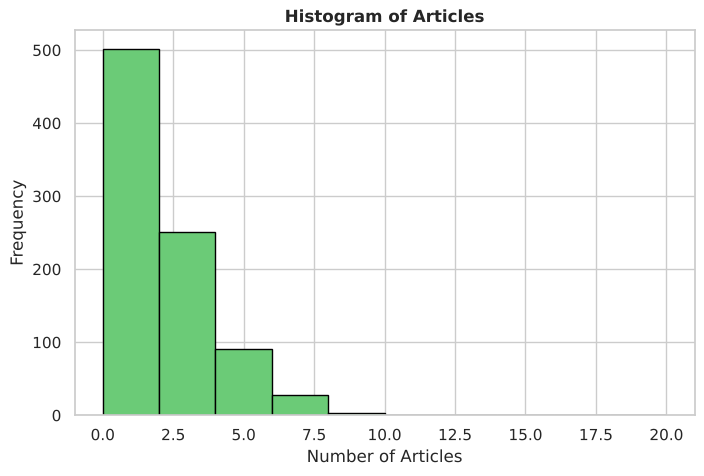

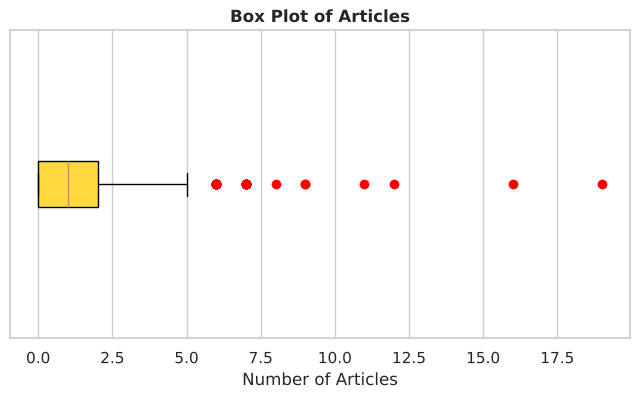

Outliers: [6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 6.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 7.0, 8.0, 9.0, 9.0, 11.0, 12.0, 16.0, 19.0]


In [ ]:
bins = pd.cut(data["articles"], bins=range(0, 22, 2), right=False, include_lowest=True)
bin_freq = bins.value_counts().sort_index()
bin_df = pd.DataFrame({"Interval": bin_freq.index.astype(str),
                       "Frequency": bin_freq.values,
                       "Relative_Freq": (bin_freq / bin_freq.sum()).round(4).values})
print(bin_df)

plt.figure(figsize=(8, 5))
plt.hist(data["articles"], bins=range(0, 22, 2), color="#6BCB77", edgecolor="black")
plt.title("Histogram of Articles", fontweight="bold")
plt.xlabel("Number of Articles"); plt.ylabel("Frequency")
plt.show()

plt.figure(figsize=(8, 4))
plt.boxplot(data["articles"], vert=False, patch_artist=True,
            boxprops={"facecolor": "#FFD93D"},
            flierprops={"marker": "o", "markerfacecolor": "red", "markeredgecolor": "red"})
plt.title("Box Plot of Articles", fontweight="bold")
plt.xlabel("Number of Articles"); plt.yticks([])
plt.show()

# outliers (same 1.5*IQR rule as boxplot.stats)
q1, q3 = data["articles"].quantile([0.25, 0.75])
out = data["articles"][(data["articles"] < q1 - 1.5 * (q3 - q1)) | (data["articles"] > q3 + 1.5 * (q3 - q1))]
print("Outliers:", sorted(out.tolist()))

### 6. Two categorical variables: Contingency table and row / column percentages

In [ ]:
cont_table = pd.crosstab(data["gender"], data["married"])
print(cont_table, "\n")
print(pd.crosstab(data["gender"], data["married"], margins=True, margins_name="Sum"), "\n")   # addmargins

row_pct = (pd.crosstab(data["gender"], data["married"], normalize="index") * 100).round(2)
print("Row %:\n", row_pct, "\n")
col_pct = (pd.crosstab(data["gender"], data["married"], normalize="columns") * 100).round(2)
print("Column %:\n", col_pct)

married   no  yes
gender           
female   189  216
male     109  365 

married   no  yes  Sum
gender                
female   189  216  405
male     109  365  474
Sum      298  581  879 

Row %:
 married     no    yes
gender               
female   46.67  53.33
male     23.00  77.00 

Column %:
 married     no    yes
gender               
female   63.42  37.18
male     36.58  62.82


### 7. Stacked Bar Plot and Grouped Bar Plot to visualize the relationship

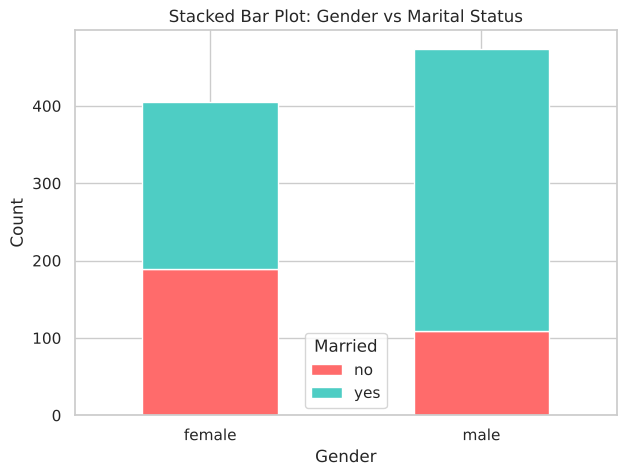

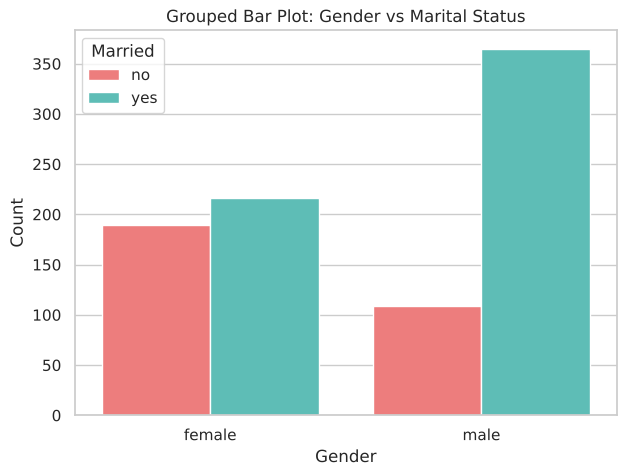

In [ ]:
pal = {"no": "#FF6B6B", "yes": "#4ECDC4"}

cont_table.plot(kind="bar", stacked=True, color=[pal["no"], pal["yes"]], figsize=(7, 5), rot=0)
plt.title("Stacked Bar Plot: Gender vs Marital Status")
plt.xlabel("Gender"); plt.ylabel("Count"); plt.legend(title="Married")
plt.show()

plt.figure(figsize=(7, 5))
sns.countplot(data=data, x="gender", hue="married", palette=pal)
plt.title("Grouped Bar Plot: Gender vs Marital Status")
plt.xlabel("Gender"); plt.ylabel("Count"); plt.legend(title="Married")
plt.show()

### 8. One categorical + one numerical variable: grouped mean, median and SD

In [ ]:
mean_grp   = data.groupby("gender", observed=True)["articles"].mean()
median_grp = data.groupby("gender", observed=True)["articles"].median()
sd_grp     = data.groupby("gender", observed=True)["articles"].std()
print(mean_grp, "\n", median_grp, "\n", sd_grp)

group_stats = pd.DataFrame({"Mean": mean_grp.round(4),
                            "Median": median_grp,
                            "SD": sd_grp.round(4)}).reset_index()
print(group_stats)

gender
female    1.469136
male      1.856540
Name: articles, dtype: float64 
 gender
female    1.0
male      1.0
Name: articles, dtype: float64 
 gender
female    1.509757
male      2.146951
Name: articles, dtype: float64
   gender    Mean  Median      SD
0  female  1.4691     1.0  1.5098
1    male  1.8565     1.0  2.1470


### 9. Side-by-side Box Plots and a Violin Plot

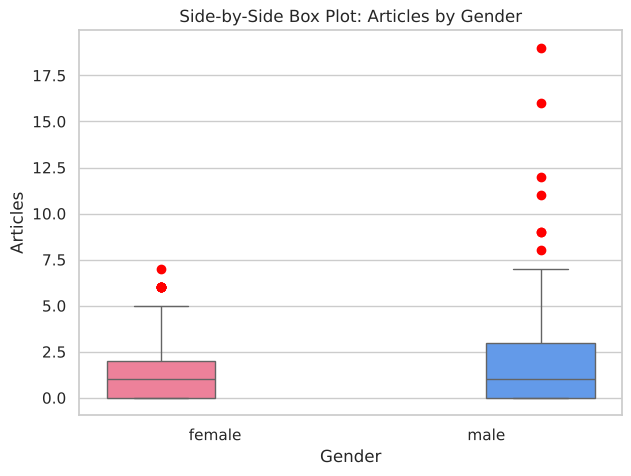

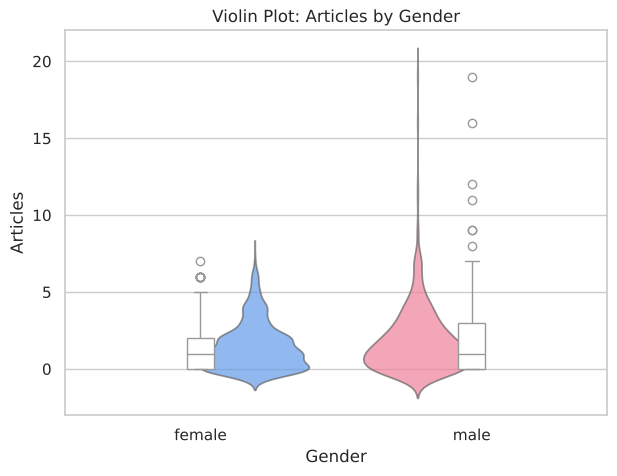

In [ ]:
gpal = {"female": "#FF6F91", "male": "#4D96FF"}

plt.figure(figsize=(7, 5))
sns.boxplot(data=data, x="gender", y="articles", hue="gender", palette=gpal,
            flierprops={"markerfacecolor": "red", "markeredgecolor": "red"})
plt.title("Side-by-Side Box Plot: Articles by Gender")
plt.xlabel("Gender"); plt.ylabel("Articles")
plt.show()

plt.figure(figsize=(7, 5))
sns.violinplot(data=data, x="gender", y="articles", hue="gender", palette=gpal, cut=3, inner=None, alpha=0.7)
sns.boxplot(data=data, x="gender", y="articles", width=0.1, color="white")
plt.title("Violin Plot: Articles by Gender")
plt.xlabel("Gender"); plt.ylabel("Articles")
plt.show()

### 10. Two numerical variables: Pearson & Spearman correlation + Scatter plot with linear trend line

Pearson : 0.3123219887818019
Spearman: 0.29857257101777


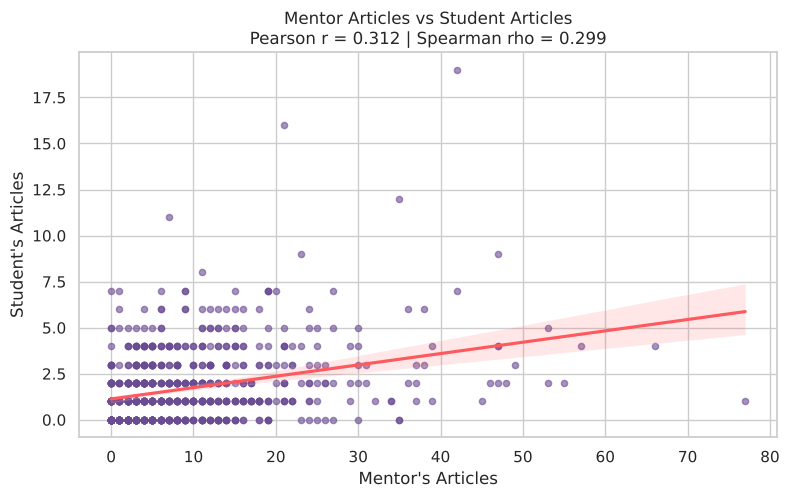

In [ ]:
pearson_r  = data["mentor"].corr(data["articles"], method="pearson")
spearman_r = data["mentor"].corr(data["articles"], method="spearman")
print("Pearson :", pearson_r)
print("Spearman:", spearman_r)

plt.figure(figsize=(9, 5))
sns.regplot(data=data, x="mentor", y="articles",
            scatter_kws={"color": "#6A4C93", "alpha": 0.6, "s": 20},
            line_kws={"color": "#FF595E"})
plt.title(f"Mentor Articles vs Student Articles\nPearson r = {pearson_r:.3f} | Spearman rho = {spearman_r:.3f}")
plt.xlabel("Mentor's Articles"); plt.ylabel("Student's Articles")
plt.show()

### 11. Two categorical + one numerical: Mean & SD for all combinations, Faceted Box Plot, Grouped Bar Chart with Error Bars

   gender married    Mean      SD
0  female      no  1.4180  1.5193
1  female     yes  1.5139  1.5034
2    male      no  1.9541  2.0339
3    male     yes  1.8274  2.1814


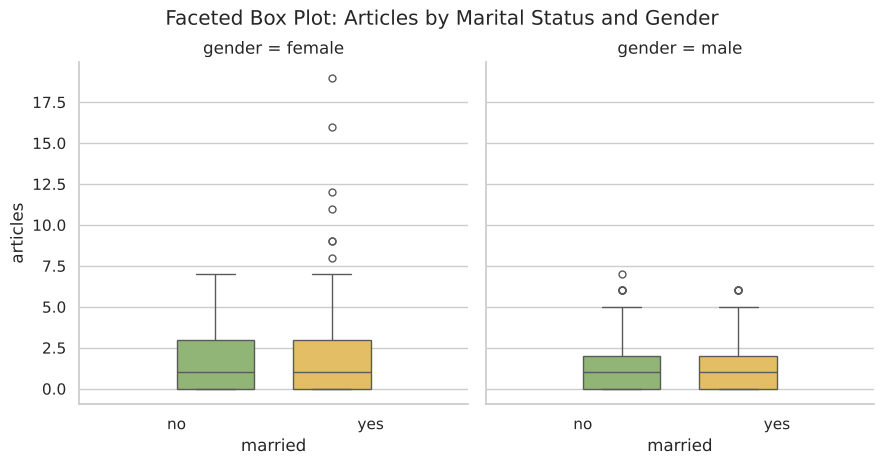

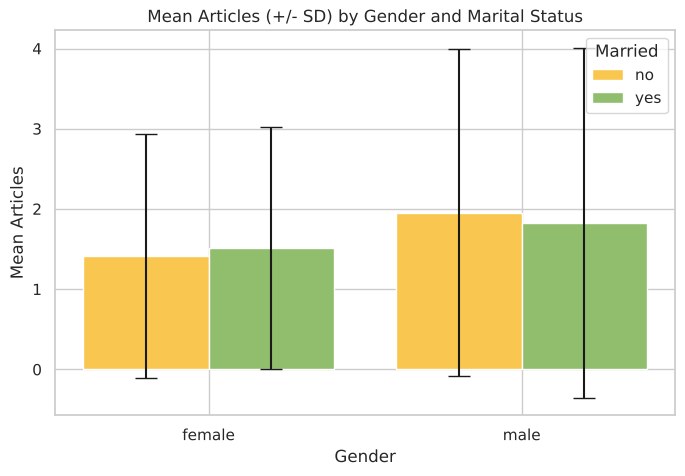

In [ ]:
combo_stats = (data.groupby(["gender", "married"], observed=True)["articles"]
                   .agg(Mean="mean", SD="std").round(4).reset_index())
print(combo_stats)

mpal = {"no": "#F9C74F", "yes": "#90BE6D"}
g = sns.catplot(data=data, x="married", y="articles", hue="married", col="gender",
                kind="box", palette=mpal, height=4.5)
g.figure.suptitle("Faceted Box Plot: Articles by Marital Status and Gender", y=1.03)
plt.show()

# Grouped bar chart with +/- SD error bars
fig, ax = plt.subplots(figsize=(8, 5))
genders = combo_stats["gender"].unique()
xpos = np.arange(len(genders))
w = 0.4
for i, m in enumerate(["no", "yes"]):
    s = combo_stats[combo_stats["married"] == m].set_index("gender").loc[genders]
    ax.bar(xpos + (i - 0.5) * w, s["Mean"], w, yerr=s["SD"], capsize=8,
           color=mpal[m], label=m)
ax.set_xticks(xpos, genders)
ax.set_title("Mean Articles (+/- SD) by Gender and Marital Status")
ax.set_xlabel("Gender"); ax.set_ylabel("Mean Articles"); ax.legend(title="Married")
plt.show()

### 12. One categorical + two numerical: coloured/shaped scatter plot and correlation per category

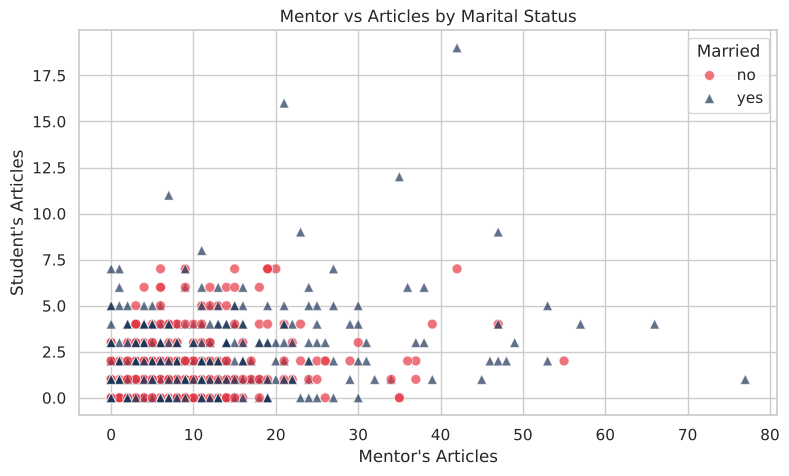

married: no
           mentor  articles
mentor    1.00000   0.26238
articles  0.26238   1.00000 
----------------------------------------
married: yes
            mentor  articles
mentor    1.000000  0.331637
articles  0.331637  1.000000 
----------------------------------------


In [ ]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=data, x="mentor", y="articles", hue="married", style="married",
                palette={"no": "#E63946", "yes": "#1D3557"}, markers={"no": "o", "yes": "^"},
                s=50, alpha=0.7)
plt.title("Mentor vs Articles by Marital Status")
plt.xlabel("Mentor's Articles"); plt.ylabel("Student's Articles")
plt.legend(title="Married")
plt.show()

for level, grp in data.groupby("married", observed=True):
    print(f"married: {level}")
    print(grp[["mentor", "articles"]].corr(), "\n" + "-" * 40)

### 13. At least 3 numerical features: full correlation matrix plotted as a heatmap

          articles    kids  prestige  mentor
articles    1.0000 -0.0584    0.0720  0.3123
kids       -0.0584  1.0000   -0.0318  0.0402
prestige    0.0720 -0.0318    1.0000  0.2546
mentor      0.3123  0.0402    0.2546  1.0000


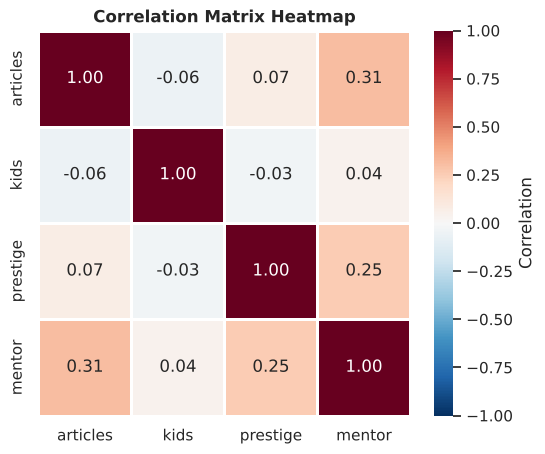

In [ ]:
num_data = data[["articles", "kids", "prestige", "mentor"]]
cor_matrix = num_data.corr()
print(cor_matrix.round(4))

plt.figure(figsize=(6, 5))
sns.heatmap(cor_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
            linewidths=1, linecolor="white", cbar_kws={"label": "Correlation"})
plt.title("Correlation Matrix Heatmap", fontweight="bold")
plt.show()

### 14. Pairs Plot / Scatterplot Matrix

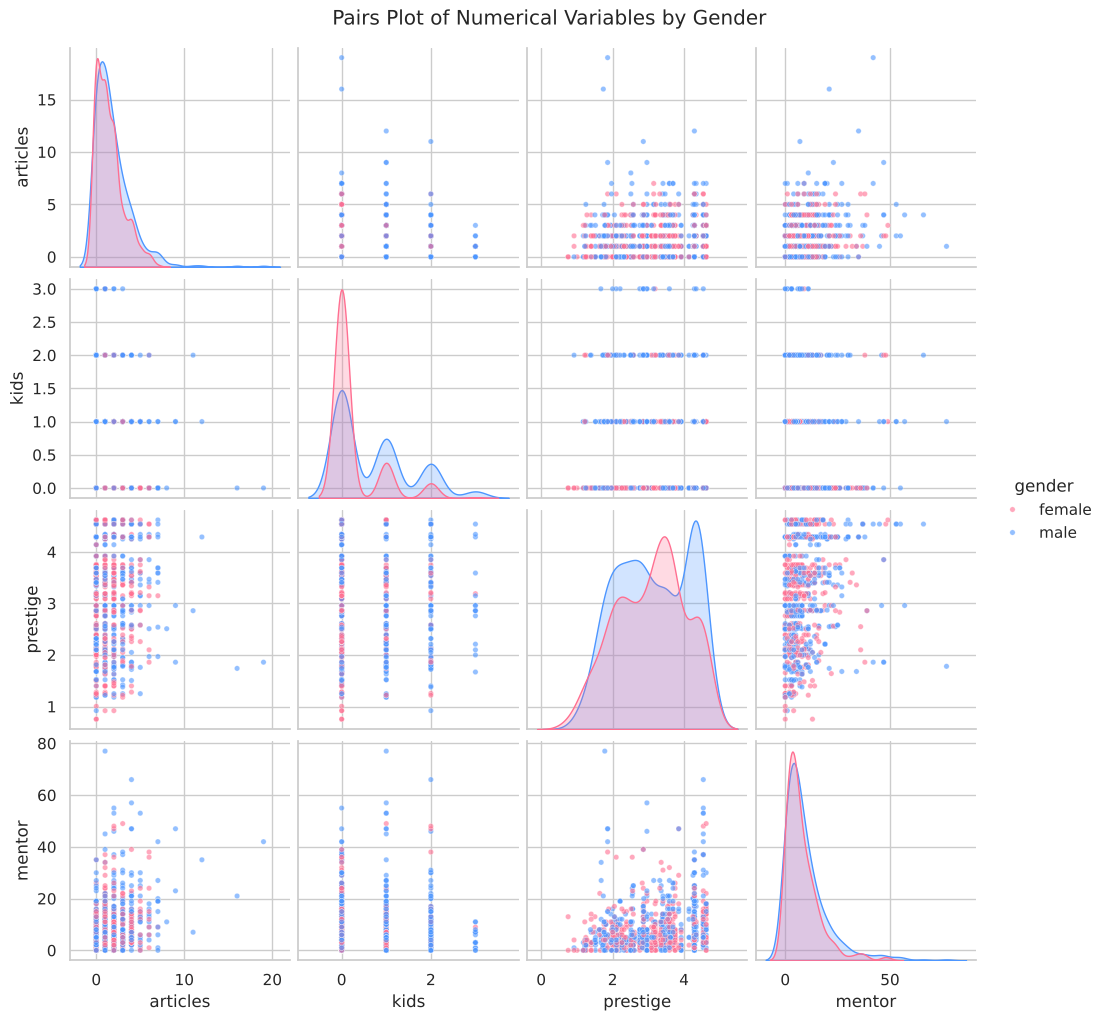

In [ ]:
g = sns.pairplot(data, vars=["articles", "kids", "prestige", "mentor"], hue="gender",
                 palette=gpal, plot_kws={"alpha": 0.6, "s": 15})
g.figure.suptitle("Pairs Plot of Numerical Variables by Gender", y=1.02)
plt.show()

---
# DA-8 : K-Means and Hierarchical Clustering
## K-Means Clustering
### 1. Load the dataset

In [ ]:
from sklearn.cluster import KMeans

data = pd.read_csv(CSV_PATH, na_values=["", "NA"])
data = data.drop(columns="rownames")
print(data.shape)

(915, 6)


### 2. View the dataset

In [ ]:
display(data.head())
data.info()
display(data.describe(include="all"))

,articles,gender,married,kids,prestige,mentor
0,0.0,male,yes,0.0,2.52,7.0
1,0.0,female,no,0.0,2.05,6.0
2,0.0,female,no,0.0,3.75,6.0
3,0.0,male,yes,1.0,1.18,3.0
4,0.0,female,no,0.0,3.75,26.0


<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   articles  913 non-null    float64
 1   gender    910 non-null    str    
 2   married   905 non-null    str    
 3   kids      909 non-null    float64
 4   prestige  904 non-null    float64
 5   mentor    913 non-null    float64
dtypes: float64(4), str(2)
memory usage: 43.0 KB


,articles,gender,married,kids,prestige,mentor
count,913.000000,910,905,909.000000,904.000000,913.000000
unique,NaN,2,2,NaN,NaN,NaN
top,NaN,male,yes,NaN,NaN,NaN
freq,NaN,492,598,NaN,NaN,NaN
mean,1.695509,NaN,NaN,0.492849,3.111753,8.782037
std,1.927226,NaN,NaN,0.764870,0.981712,9.488545
min,0.000000,NaN,NaN,0.000000,0.755000,0.000000
25%,0.000000,NaN,NaN,0.000000,2.260000,3.000000
50%,1.000000,NaN,NaN,0.000000,3.190000,6.000000
75%,2.000000,NaN,NaN,1.000000,3.920000,12.000000


### 3. Check missing values

In [ ]:
print(data.isna().sum())
print("Total:", data.isna().sum().sum())
data = data.dropna().reset_index(drop=True)
print("After removal:", data.isna().sum().sum())
print(data.shape)

articles     2
gender       5
married     10
kids         6
prestige    11
mentor       2
dtype: int64
Total: 36
After removal: 0
(879, 6)


### 4. Check the dependent variable distribution (table)

In [ ]:
print(data["articles"].value_counts().sort_index())
print(data["articles"].value_counts(normalize=True).sort_index().round(4))

articles
0.0     264
1.0     238
2.0     170
3.0      81
4.0      65
5.0      26
6.0      16
7.0      12
8.0       1
9.0       2
11.0      1
12.0      1
16.0      1
19.0      1
Name: count, dtype: int64
articles
0.0     0.3003
1.0     0.2708
2.0     0.1934
3.0     0.0922
4.0     0.0739
5.0     0.0296
6.0     0.0182
7.0     0.0137
8.0     0.0011
9.0     0.0023
11.0    0.0011
12.0    0.0011
16.0    0.0011
19.0    0.0011
Name: proportion, dtype: float64


### 5. Select only numerical features for K-Means clustering

In [ ]:
num_data = data.select_dtypes(include="number")
print(num_data.columns.tolist())
print(num_data.shape)
num_data.head()

['articles', 'kids', 'prestige', 'mentor']
(879, 4)


,articles,kids,prestige,mentor
0,0.0,0.0,2.52,7.0
1,0.0,0.0,2.05,6.0
2,0.0,0.0,3.75,6.0
3,0.0,1.0,1.18,3.0
4,0.0,0.0,3.75,26.0


### 6. Standardize the data (scale)

In [ ]:
scaled_data = (num_data - num_data.mean()) / num_data.std()     # same as R scale()
display(scaled_data.head())
print(scaled_data.mean().round(4))
print(scaled_data.std())

,articles,kids,prestige,mentor
0,-0.888196,-0.651855,-0.599150,-0.195873
1,-0.888196,-0.651855,-1.077533,-0.300283
2,-0.888196,-0.651855,0.652786,-0.300283
3,-0.888196,0.650374,-1.963049,-0.613514
4,-0.888196,-0.651855,0.652786,1.787920


articles    0.0
kids        0.0
prestige    0.0
mentor      0.0
dtype: float64
articles    1.0
kids        1.0
prestige    1.0
mentor      1.0
dtype: float64


### 7. Apply K-Means Clustering with 2 centers

In [ ]:
km2 = KMeans(n_clusters=2, n_init=25, random_state=123).fit(scaled_data)
print("Cluster sizes:", np.bincount(km2.labels_))

Cluster sizes: [616 263]


### 8. Display K-Means results

In [ ]:
def kmeans_report(km, X):
    labels = km.labels_
    centers = pd.DataFrame(km.cluster_centers_, columns=X.columns, index=range(1, km.n_clusters + 1))
    withinss = [((X[labels == k] - km.cluster_centers_[k]) ** 2).values.sum() for k in range(km.n_clusters)]
    totss = ((X - X.mean()) ** 2).values.sum()
    print(f"K-means clustering with {km.n_clusters} clusters of sizes {list(np.bincount(labels))}\n")
    print("Cluster means:\n", centers, "\n")
    print("Clustering vector:\n", labels + 1, "\n")
    print("Within cluster sum of squares by cluster:\n", np.round(withinss, 3))
    print(f" (between_SS / total_SS = {(totss - km.inertia_) / totss * 100:.1f} %)")

kmeans_report(km2, scaled_data)

K-means clustering with 2 clusters of sizes [np.int64(616), np.int64(263)]

Cluster means:
    articles      kids  prestige    mentor
1 -0.353736  0.071136 -0.313322 -0.392320
2  0.828522 -0.166614  0.733865  0.918894 

Clustering vector:
 [1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 2 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1
 1 1 1 1 1 1 1 2 1 1 1 1 1 1 2 1 1 1 1 2 1 2 1 1 1 2 1 1 1 1 1 2 1 1 1 1 1
 1 1 1 2 2 2 1 1 1 1 1 1 1 1 1 2 1 1 1 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 2 1 1 1 1 1 1 1 1 1 1 1 2 2 2 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 2 1 1
 1 1 1 1 2

### 9. Display cluster centers

In [ ]:
print(pd.DataFrame(km2.cluster_centers_, columns=num_data.columns, index=[1, 2]))
num_data.groupby(km2.labels_ + 1).mean().rename_axis("Cluster")

   articles      kids  prestige    mentor
1 -0.353736  0.071136 -0.313322 -0.392320
2  0.828522 -0.166614  0.733865  0.918894


,articles,kids,prestige,mentor
Cluster,,,,
1,1.009740,0.555195,2.800820,5.118506
2,3.243346,0.372624,3.829658,17.676806


### 10. Calculate WCSS for K = 1 to 10

In [ ]:
wcss = [KMeans(n_clusters=k, n_init=25, random_state=123).fit(scaled_data).inertia_
        for k in range(1, 11)]
wcss_df = pd.DataFrame({"K": range(1, 11), "WCSS": np.round(wcss, 2)})
print(wcss_df)

    K     WCSS
0   1  3512.00
1   2  2724.97
2   3  2158.59
3   4  1737.87
4   5  1481.57
5   6  1348.66
6   7  1224.40
7   8  1127.77
8   9  1041.63
9  10   980.37


### 11. Display the elbow plot

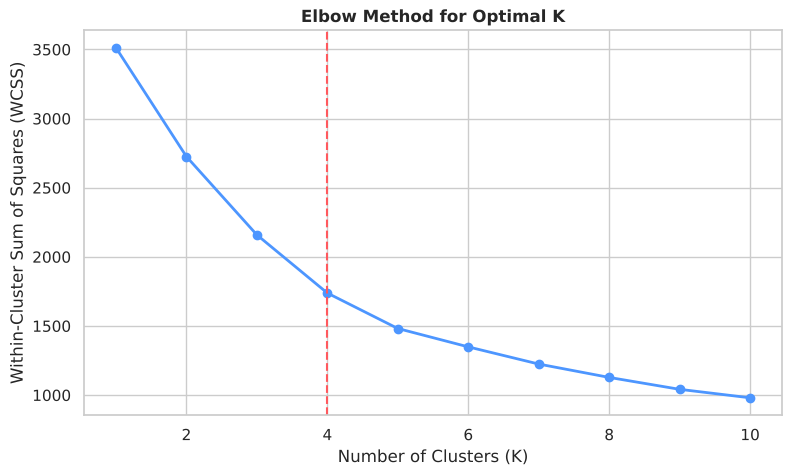

In [ ]:
plt.figure(figsize=(9, 5))
plt.plot(range(1, 11), wcss, "o-", color="#4D96FF", linewidth=2)
plt.axvline(4, linestyle="--", color="#FF595E")
plt.title("Elbow Method for Optimal K", fontweight="bold")
plt.xlabel("Number of Clusters (K)"); plt.ylabel("Within-Cluster Sum of Squares (WCSS)")
plt.show()

### 12. Apply K-means clustering based on the elbow recommendation (K = 4)

Sizes: [107 321 110 341]
   articles    kids  prestige  mentor
1   -0.2748  2.1473   -0.1099 -0.1842
2   -0.2649 -0.3111   -0.9579 -0.3940
3    1.4456 -0.1428    0.5323  1.7974
4   -0.1307 -0.3349    0.7645 -0.1512
between_SS / total_SS (%): 50.52


,articles,kids,prestige,mentor
Cluster,,,,
1,1.158879,2.149533,3.000701,7.112150
2,1.177570,0.261682,2.167539,5.102804
3,4.409091,0.390909,3.631636,26.090909
4,1.431085,0.243402,3.859736,7.428152


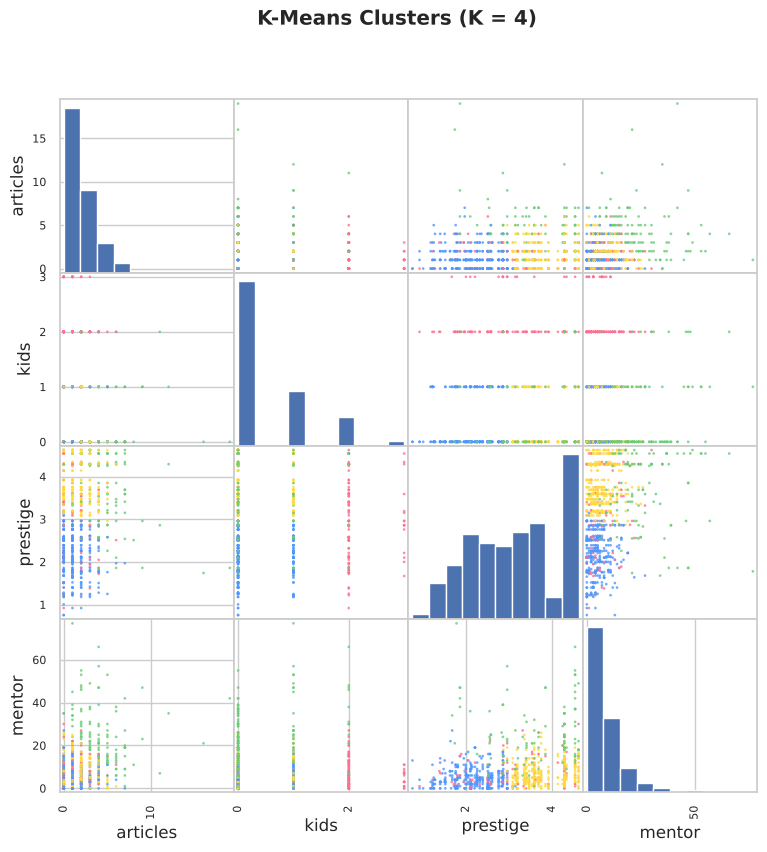

In [ ]:
km_final = KMeans(n_clusters=4, n_init=25, random_state=123).fit(scaled_data)
print("Sizes:", np.bincount(km_final.labels_))
print(pd.DataFrame(km_final.cluster_centers_, columns=num_data.columns, index=range(1, 5)).round(4))
totss = ((scaled_data - scaled_data.mean()) ** 2).values.sum()
print("between_SS / total_SS (%):", round((totss - km_final.inertia_) / totss * 100, 2))
display(num_data.groupby(km_final.labels_ + 1).mean().rename_axis("Cluster"))

colors = np.array(["#FF6F91", "#4D96FF", "#6BCB77", "#FFD93D"])[km_final.labels_]
pd.plotting.scatter_matrix(num_data, c=colors, figsize=(9, 9), diagonal="hist", alpha=0.8, s=15)
plt.suptitle("K-Means Clusters (K = 4)", fontweight="bold")
plt.show()

## Hierarchical Clustering
### 1. Load the dataset

In [ ]:
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster

data = pd.read_csv(CSV_PATH, na_values=["", "NA"])
data = data.drop(columns="rownames")
print(data.shape)

(915, 6)


### 2. View the dataset

In [ ]:
display(data.head())
data.info()

,articles,gender,married,kids,prestige,mentor
0,0.0,male,yes,0.0,2.52,7.0
1,0.0,female,no,0.0,2.05,6.0
2,0.0,female,no,0.0,3.75,6.0
3,0.0,male,yes,1.0,1.18,3.0
4,0.0,female,no,0.0,3.75,26.0


<class 'pandas.DataFrame'>
RangeIndex: 915 entries, 0 to 914
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   articles  913 non-null    float64
 1   gender    910 non-null    str    
 2   married   905 non-null    str    
 3   kids      909 non-null    float64
 4   prestige  904 non-null    float64
 5   mentor    913 non-null    float64
dtypes: float64(4), str(2)
memory usage: 43.0 KB


### 3. Check missing values

In [ ]:
print(data.isna().sum())
print("Total:", data.isna().sum().sum())
data = data.dropna().reset_index(drop=True)
print("After removal:", data.isna().sum().sum())
print(data.shape)

articles     2
gender       5
married     10
kids         6
prestige    11
mentor       2
dtype: int64
Total: 36
After removal: 0
(879, 6)


### 4. Select only numerical attributes

In [ ]:
num_data = data.select_dtypes(include="number")
print(num_data.columns.tolist())
num_data.head()

['articles', 'kids', 'prestige', 'mentor']


,articles,kids,prestige,mentor
0,0.0,0.0,2.52,7.0
1,0.0,0.0,2.05,6.0
2,0.0,0.0,3.75,6.0
3,0.0,1.0,1.18,3.0
4,0.0,0.0,3.75,26.0


### 5. Standardize the data (scale)

In [ ]:
scaled_data = (num_data - num_data.mean()) / num_data.std()
scaled_data.head()

,articles,kids,prestige,mentor
0,-0.888196,-0.651855,-0.599150,-0.195873
1,-0.888196,-0.651855,-1.077533,-0.300283
2,-0.888196,-0.651855,0.652786,-0.300283
3,-0.888196,0.650374,-1.963049,-0.613514
4,-0.888196,-0.651855,0.652786,1.787920


### 6. Calculate Euclidean distance (dist)

In [ ]:
dist_matrix = pdist(scaled_data, metric="euclidean")
print("Number of pairwise distances:", len(dist_matrix))
print(np.round(squareform(dist_matrix)[:6, :6], 4))

Number of pairwise distances: 385881
[[0.     0.4896 1.2563 1.9314 2.3458 2.8709]
 [0.4896 0.     1.7303 1.6056 2.7119 3.0683]
 [1.2563 1.7303 0.     2.9388 2.0882 2.6428]
 [1.9314 1.6056 2.9388 0.     3.7822 2.7792]
 [2.3458 2.7119 2.0882 3.7822 0.     3.6179]
 [2.8709 3.0683 2.6428 2.7792 3.6179 0.    ]]


### 7. Perform Hierarchical Clustering using Ward's method (hclust, ward.D2)

In [ ]:
hc = linkage(dist_matrix, method="ward")      # scipy 'ward' == R 'ward.D2'
print("Cluster method   : ward.D2")
print("Distance         : euclidean")
print("Number of objects:", len(scaled_data))

Cluster method   : ward.D2
Distance         : euclidean
Number of objects: 879


### 8. Plot the dendrogram

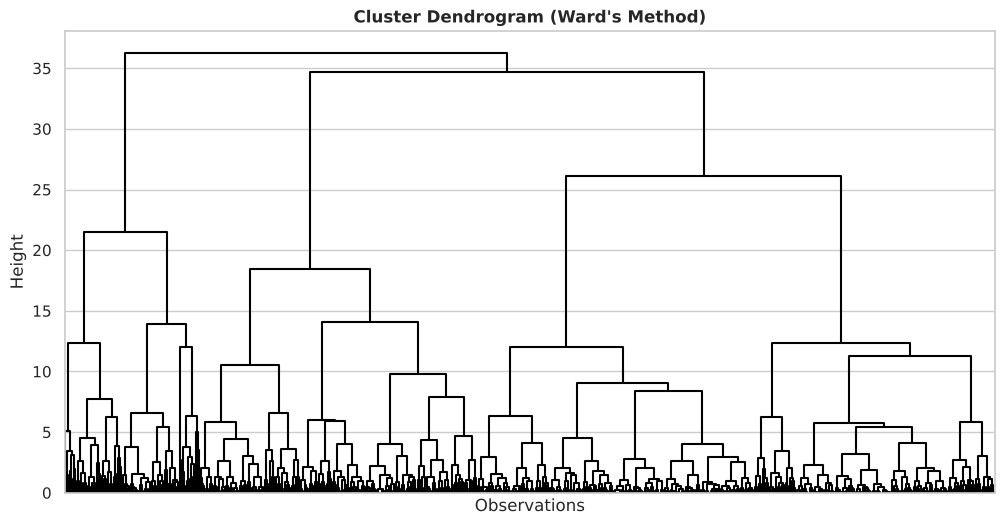

In [ ]:
plt.figure(figsize=(12, 6))
dendrogram(hc, no_labels=True, color_threshold=0, above_threshold_color="black")
plt.title("Cluster Dendrogram (Ward's Method)", fontweight="bold")
plt.xlabel("Observations"); plt.ylabel("Height")
plt.show()

### 9. Divide the data into 3 clusters and display cluster assignments (cutree)

[3 3 3 2 3 2 3 2 3 3 3 3 2 3 3 3 2 3 3 3 2 2 2 2 3 2 2 3 3 3 3 3 3 2 3 3 2
 3 3 3 2 3 2 3 3 3 3 3 2 2 3 2 3 2 2 3 3 2 3 3 2 3 3 2 3 3 2 3 3 3 2 2 2 2
 3 3 2 3 3 3 2 1 2 3 2 2 3 3 3 3 3 3 2 3 3 2 3 2 2 3 3 2 2 3 3 2 3 2 2 3 2
 3 2 3 3 2 3 3 3 2 3 3 3 3 3 3 2 3 2 3 3 2 3 2 3 3 2 3 2 3 3 3 2 3 3 3 2 3
 2 2 3 3 3 3 3 2 3 3 3 3 3 3 3 3 3 3 3 2 3 3 3 2 2 2 3 3 2 3 2 3 3 3 3 2 3
 3 2 3 3 2 3 2 2 2 2 3 3 2 3 3 2 3 2 3 2 2 3 3 3 3 3 2 3 3 3 3 3 2 3 3 3 3
 2 3 3 3 3 3 2 2 3 3 2 3 3 3 2 3 3 3 3 3 3 3 3 3 2 3 3 2 2 2 3 2 3 2 1 2 3
 3 3 2 3 2 3 2 2 2 2 3 3 2 3 3 3 3 3 2 3 3 3 3 3 3 3 2 3 3 3 3 1 3 2 3 3 3
 3 2 2 3 3 3 3 3 3 3 3 3 3 3 3 2 2 3 2 1 3 2 3 3 3 3 3 2 2 2 2 3 3 3 2 3 2
 2 3 2 3 3 2 2 2 2 2 3 3 2 3 3 3 3 3 2 3 3 2 3 3 3 2 2 3 2 3 3 3 3 3 3 3 2
 3 3 3 3 3 3 2 3 2 2 3 2 3 3 3 3 1 3 3 3 3 3 2 1 2 2 3 2 2 3 3 3 3 2 3 3 3
 2 2 2 2 2 3 3 3 2 2 3 3 2 3 3 3 3 2 2 3 2 3 3 2 3 2 3 3 3 3 3 3 1 3 3 3 3
 2 3 3 3 3 3 2 3 3 1 3 3 3 3 2 3 2 3 3 3 3 1 3 3 3 3 3 2 3 3 3 2 3 2 3 3 2
 3 2 3 2 2 2 2 2 1 3 2 3 

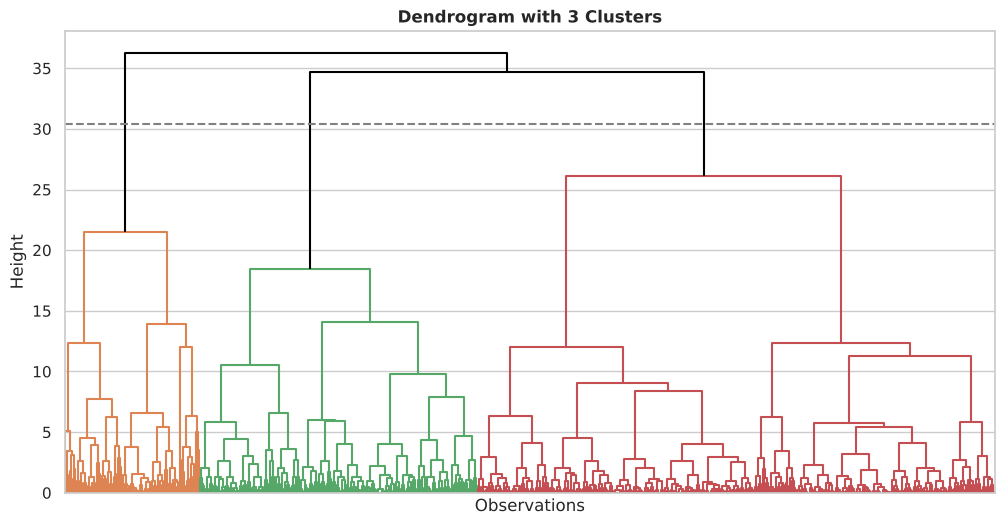

In [ ]:
clusters = fcluster(hc, t=3, criterion="maxclust")
print(clusters)

cut_height = (hc[-3, 2] + hc[-2, 2]) / 2          # height that gives 3 clusters
plt.figure(figsize=(12, 6))
dendrogram(hc, no_labels=True, color_threshold=cut_height, above_threshold_color="black")
plt.axhline(cut_height, linestyle="--", color="grey")
plt.title("Dendrogram with 3 Clusters", fontweight="bold")
plt.xlabel("Observations"); plt.ylabel("Height")
plt.show()

### 10. Display number of samples in each cluster (table)

In [ ]:
print(pd.Series(clusters).value_counts().sort_index())
num_data.groupby(clusters).mean().rename_axis("Cluster")

1    127
2    263
3    489
Name: count, dtype: int64


,articles,kids,prestige,mentor
Cluster,,,,
1,4.566929,0.314961,3.594488,21.692913
2,1.262357,1.467681,3.037890,6.486692
3,1.151329,0.028630,3.020532,6.832311


---
# DA-9 : Principal Component Analysis (mtcars)
`mtcars` is built into R; the six required columns are entered below.
### 1. Select mpg, disp, hp, drat, wt, qsec and examine their basic statistical characteristics

In [ ]:
from sklearn.decomposition import PCA

mtcars = pd.DataFrame({
    "mpg":  [21.0, 21.0, 22.8, 21.4, 18.7, 18.1, 14.3, 24.4, 22.8, 19.2, 17.8, 16.4, 17.3, 15.2, 10.4, 10.4,
             14.7, 32.4, 30.4, 33.9, 21.5, 15.5, 15.2, 13.3, 19.2, 27.3, 26.0, 30.4, 15.8, 19.7, 15.0, 21.4],
    "disp": [160.0, 160.0, 108.0, 258.0, 360.0, 225.0, 360.0, 146.7, 140.8, 167.6, 167.6, 275.8, 275.8, 275.8, 472.0, 460.0,
             440.0, 78.7, 75.7, 71.1, 120.1, 318.0, 304.0, 350.0, 400.0, 79.0, 120.3, 95.1, 351.0, 145.0, 301.0, 121.0],
    "hp":   [110, 110, 93, 110, 175, 105, 245, 62, 95, 123, 123, 180, 180, 180, 205, 215,
             230, 66, 52, 65, 97, 150, 150, 245, 175, 66, 91, 113, 264, 175, 335, 109],
    "drat": [3.90, 3.90, 3.85, 3.08, 3.15, 2.76, 3.21, 3.69, 3.92, 3.92, 3.92, 3.07, 3.07, 3.07, 2.93, 3.00,
             3.23, 4.08, 4.93, 4.22, 3.70, 2.76, 3.15, 3.73, 3.08, 4.08, 4.43, 3.77, 4.22, 3.62, 3.54, 4.11],
    "wt":   [2.620, 2.875, 2.320, 3.215, 3.440, 3.460, 3.570, 3.190, 3.150, 3.440, 3.440, 4.070, 3.730, 3.780, 5.250, 5.424,
             5.345, 2.200, 1.615, 1.835, 2.465, 3.520, 3.435, 3.840, 3.845, 1.935, 2.140, 1.513, 3.170, 2.770, 3.570, 2.780],
    "qsec": [16.46, 17.02, 18.61, 19.44, 17.02, 20.22, 15.84, 20.00, 22.90, 18.30, 18.90, 17.40, 17.60, 18.00, 17.98, 17.82,
             17.42, 19.47, 18.52, 19.90, 20.01, 16.87, 17.30, 15.41, 17.05, 18.90, 16.70, 16.90, 14.50, 15.50, 14.60, 18.60],
}, index=["Mazda RX4", "Mazda RX4 Wag", "Datsun 710", "Hornet 4 Drive", "Hornet Sportabout", "Valiant",
          "Duster 360", "Merc 240D", "Merc 230", "Merc 280", "Merc 280C", "Merc 450SE", "Merc 450SL",
          "Merc 450SLC", "Cadillac Fleetwood", "Lincoln Continental", "Chrysler Imperial", "Fiat 128",
          "Honda Civic", "Toyota Corolla", "Toyota Corona", "Dodge Challenger", "AMC Javelin", "Camaro Z28",
          "Pontiac Firebird", "Fiat X1-9", "Porsche 914-2", "Lotus Europa", "Ford Pantera L", "Ferrari Dino",
          "Maserati Bora", "Volvo 142E"])

cars_pca = mtcars[["mpg", "disp", "hp", "drat", "wt", "qsec"]]
display(cars_pca.head())

# Basic statistical characteristics
cars_pca.describe()

,mpg,disp,hp,drat,wt,qsec
Mazda RX4,21.0,160.0,110,3.90,2.620,16.46
Mazda RX4 Wag,21.0,160.0,110,3.90,2.875,17.02
Datsun 710,22.8,108.0,93,3.85,2.320,18.61
Hornet 4 Drive,21.4,258.0,110,3.08,3.215,19.44
Hornet Sportabout,18.7,360.0,175,3.15,3.440,17.02


,mpg,disp,hp,drat,wt,qsec
count,32.000000,32.000000,32.000000,32.000000,32.000000,32.000000
mean,20.090625,230.721875,146.687500,3.596563,3.217250,17.848750
std,6.026948,123.938694,68.562868,0.534679,0.978457,1.786943
min,10.400000,71.100000,52.000000,2.760000,1.513000,14.500000
25%,15.425000,120.825000,96.500000,3.080000,2.581250,16.892500
50%,19.200000,196.300000,123.000000,3.695000,3.325000,17.710000
75%,22.800000,326.000000,180.000000,3.920000,3.610000,18.900000
max,33.900000,472.000000,335.000000,4.930000,5.424000,22.900000


### 2. Standardize the selected variables before applying PCA. Explain why standardization is required

In [ ]:
cars_scaled = (cars_pca - cars_pca.mean()) / cars_pca.std()     # same as R scale()
display(cars_scaled.head())
print("Column means:\n", cars_scaled.mean().round(10))
print("Standard deviations:\n", cars_scaled.std())

,mpg,disp,hp,drat,wt,qsec
Mazda RX4,0.150885,-0.570620,-0.535093,0.567514,-0.610400,-0.777165
Mazda RX4 Wag,0.150885,-0.570620,-0.535093,0.567514,-0.349785,-0.463781
Datsun 710,0.449543,-0.990182,-0.783040,0.474000,-0.917005,0.426007
Hornet 4 Drive,0.217253,0.220094,-0.535093,-0.966118,-0.002300,0.890487
Hornet Sportabout,-0.230735,1.043081,0.412942,-0.835198,0.227654,-0.463781


Column means:
 mpg    -0.0
disp    0.0
hp      0.0
drat   -0.0
wt     -0.0
qsec   -0.0
dtype: float64
Standard deviations:
 mpg     1.0
disp    1.0
hp      1.0
drat    1.0
wt      1.0
qsec    1.0
dtype: float64


**Why standardization is required:** PCA finds the directions of maximum *variance*, so it is sensitive to the scale of each variable. Here `disp` (≈71–472) and `hp` (≈52–335) have far larger variances than `drat` (≈2.8–4.9) or `wt` (≈1.5–5.4). Without scaling, the first components would simply follow the variables with the biggest units. Standardizing gives every variable mean 0 and standard deviation 1, so each contributes equally and PCA works on the correlation structure.

### 3. Perform PCA (prcomp)

In [ ]:
pca = PCA().fit(cars_scaled)
pc_names = [f"PC{i}" for i in range(1, 7)]

sdev = np.sqrt(pca.explained_variance_)                    # prcomp $sdev
rotation = pd.DataFrame(pca.components_.T, index=cars_pca.columns, columns=pc_names)   # prcomp $rotation
print("Standard deviations:\n", sdev.round(7))
print("\nRotation (loadings):")
print(rotation)

Standard deviations:
 [2.0463129 1.0714999 0.5773705 0.3928874 0.3532648 0.2279872]

Rotation (loadings):
           PC1       PC2       PC3       PC4       PC5       PC6
mpg  -0.458684 -0.058676 -0.194792  0.782059  0.111153  0.352493
disp  0.466035  0.060653  0.096884  0.600019 -0.294630 -0.568258
hp    0.425853 -0.361476  0.146136  0.123019  0.805741  0.047716
drat -0.367096 -0.436525  0.800492  0.022593 -0.143771 -0.112777
wt    0.438618  0.299535  0.417762  0.104383 -0.230154  0.692460
qsec -0.252832  0.762849  0.340591  0.042681  0.421875 -0.241527


### 4. Proportion of variance explained by each principal component

In [ ]:
eigenvalues = sdev ** 2
variance_proportion = eigenvalues / eigenvalues.sum()
variance_percent = variance_proportion * 100
cumulative_percent = np.cumsum(variance_percent)

variance_table = pd.DataFrame({
    "Principal_Component": pc_names,
    "Eigenvalue": eigenvalues.round(4),
    "Proportion_of_Variance": variance_proportion.round(4),
    "Percentage_Variance": variance_percent.round(2),
    "Cumulative_Percentage": cumulative_percent.round(2),
})
variance_table

,Principal_Component,Eigenvalue,Proportion_of_Variance,Percentage_Variance,Cumulative_Percentage
0,PC1,4.1874,0.6979,69.79,69.79
1,PC2,1.1481,0.1914,19.14,88.93
2,PC3,0.3334,0.0556,5.56,94.48
3,PC4,0.1544,0.0257,2.57,97.05
4,PC5,0.1248,0.0208,2.08,99.13
5,PC6,0.0520,0.0087,0.87,100.00


### 5. Minimum number of principal components required to explain at least 80% of the total variance

In [ ]:
num_components = int(np.argmax(cumulative_percent >= 80) + 1)
print("Minimum number of PCs required:", num_components)
print("Cumulative variance explained:", round(cumulative_percent[num_components - 1], 2), "%")

Minimum number of PCs required: 2
Cumulative variance explained: 88.93 %


### 6. Scree plot and interpretation

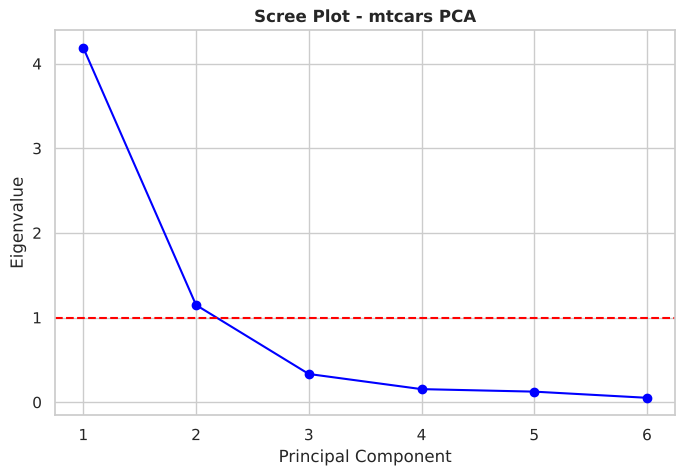

In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(range(1, 7), eigenvalues, "o-", color="blue")
plt.axhline(1, color="red", linestyle="--")
plt.title("Scree Plot - mtcars PCA", fontweight="bold")
plt.xlabel("Principal Component"); plt.ylabel("Eigenvalue")
plt.show()

**Interpretation:** The eigenvalues drop sharply from PC1 (≈4.19) to PC2 (≈1.15) and then flatten (elbow at PC3). Only PC1 and PC2 have eigenvalues above 1 (Kaiser criterion) and together explain ≈89% of the variance, so the six variables can be summarised by two components with little information loss.

### 7. PCA loadings – which variables contribute most strongly to PC1 and PC2

In [ ]:
loadings = rotation
print(loadings.round(4))

pc1_loadings = loadings["PC1"]
print("\nPC1 loadings:\n", pc1_loadings)
pc1_rank = pc1_loadings.abs().sort_values(ascending=False)     # rank by absolute loading
print("\nPC1 rank:\n", pc1_rank)

pc2_loadings = loadings["PC2"]
print("\nPC2 loadings:\n", pc2_loadings)
pc2_rank = pc2_loadings.abs().sort_values(ascending=False)
print("\nPC2 rank:\n", pc2_rank)

         PC1     PC2     PC3     PC4     PC5     PC6
mpg  -0.4587 -0.0587 -0.1948  0.7821  0.1112  0.3525
disp  0.4660  0.0607  0.0969  0.6000 -0.2946 -0.5683
hp    0.4259 -0.3615  0.1461  0.1230  0.8057  0.0477
drat -0.3671 -0.4365  0.8005  0.0226 -0.1438 -0.1128
wt    0.4386  0.2995  0.4178  0.1044 -0.2302  0.6925
qsec -0.2528  0.7628  0.3406  0.0427  0.4219 -0.2415

PC1 loadings:
 mpg    -0.458684
disp    0.466035
hp      0.425853
drat   -0.367096
wt      0.438618
qsec   -0.252832
Name: PC1, dtype: float64

PC1 rank:
 disp    0.466035
mpg     0.458684
wt      0.438618
hp      0.425853
drat    0.367096
qsec    0.252832
Name: PC1, dtype: float64

PC2 loadings:
 mpg    -0.058676
disp    0.060653
hp     -0.361476
drat   -0.436525
wt      0.299535
qsec    0.762849
Name: PC2, dtype: float64

PC2 rank:
 qsec    0.762849
drat    0.436525
hp      0.361476
wt      0.299535
disp    0.060653
mpg     0.058676
Name: PC2, dtype: float64


**Interpretation:** PC1 is driven almost equally by **disp, mpg, wt and hp** (then drat): disp, wt and hp load with one sign and mpg, drat with the opposite sign, so PC1 is a "size / power vs fuel economy" axis. PC2 is dominated by **qsec**, followed by drat and hp, so it represents acceleration (quarter-mile time). (The overall sign of a component can flip between R and Python; only the relative signs matter.)

### 8. PCA biplot and interpretation

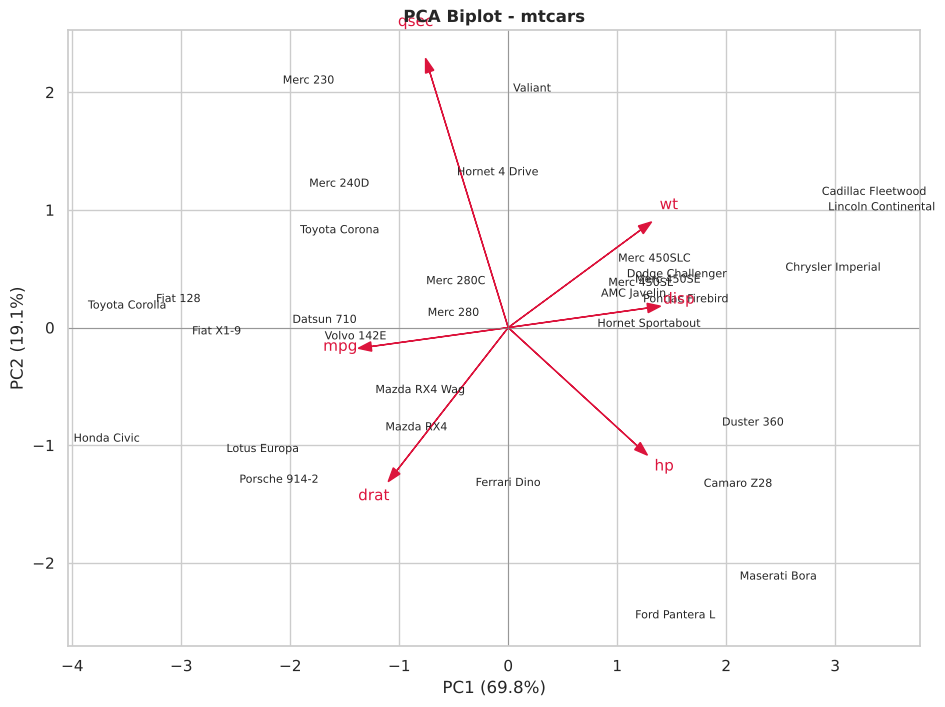

In [ ]:
pca_scores = pd.DataFrame(pca.transform(cars_scaled), index=cars_pca.index, columns=pc_names)

fig, ax = plt.subplots(figsize=(11, 8))
ax.scatter(pca_scores["PC1"], pca_scores["PC2"], s=0)
for name, (x, y) in pca_scores[["PC1", "PC2"]].iterrows():
    ax.text(x, y, name, fontsize=8, ha="center")
scale = 3.0                                    # stretch arrows to the score range
for var in loadings.index:
    lx, ly = loadings.loc[var, "PC1"] * scale, loadings.loc[var, "PC2"] * scale
    ax.arrow(0, 0, lx, ly, color="crimson", head_width=0.08, length_includes_head=True)
    ax.text(lx * 1.12, ly * 1.12, var, color="crimson", fontsize=11, ha="center")
ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
ax.set_title("PCA Biplot - mtcars", fontweight="bold")
ax.set_xlabel(f"PC1 ({variance_percent[0]:.1f}%)"); ax.set_ylabel(f"PC2 ({variance_percent[1]:.1f}%)")
plt.show()

**Interpretation:** Arrows for disp, wt and hp point in the same direction (strongly positively correlated) and opposite to mpg (and drat), so heavy, powerful cars have low fuel economy. Large cars such as Cadillac Fleetwood, Lincoln Continental and Chrysler Imperial lie on the disp/wt side, while small economical cars (Toyota Corolla, Fiat 128, Honda Civic) lie on the mpg side. Along PC2, cars with high qsec (slow acceleration, e.g. Merc 230, Valiant) are separated from fast sports cars with low qsec (Maserati Bora, Ford Pantera L).

### PCA scores

In [ ]:
pca_scores.head()

,PC1,PC2,PC3,PC4,PC5,PC6
Mazda RX4,-0.842581,-0.873469,-0.228278,-0.374273,-0.515226,0.052939
Mazda RX4 Wag,-0.807504,-0.556342,-0.012668,-0.333693,-0.442999,0.157713
Datsun 710,-1.685045,0.040007,-0.156494,-0.405716,0.033404,-0.107561
Hornet 4 Drive,-0.096444,1.294378,-0.570230,0.252079,0.043260,-0.181735
Hornet Sportabout,1.291510,0.006517,-0.525074,0.481319,-0.128221,-0.290519
